# Sesión 1 — MUBD

## Manejo básico de Python y estadística descriptiva

En esta sesión pasaremos de **expresiones y funciones** a **vectores, matrices y tablas**; después leeremos ficheros y describiremos variables numéricas y categóricas, por separado y conjuntamente. El hilo conductor es una muestra de estudiantes y sus teléfonos móviles. Cada bloque explica **qué pregunta responde**, muestra un ejemplo reproducible y propone qué conviene observar en su resultado.

**Cómo trabajar:** ejecuta las celdas de arriba abajo y prueba a cambiar los parámetros de los ejemplos. Una variable creada en una celda permanece en el kernel y puede usarse más adelante. Si modificas un paso anterior, vuelve a ejecutar los pasos dependientes; para reproducir todo desde cero, reinicia el kernel y ejecuta el cuaderno en orden.

Los apartados titulados **Ejercicio** contienen pistas y espacio para trabajar, pero **no incluyen soluciones**. Las expresiones matemáticas se muestran en línea como $x$ o, cuando conviene destacar una relación, en ecuaciones independientes.

### Trabajar en VS Code

1. Abre la carpeta del proyecto y selecciona un kernel de Python en la esquina superior derecha; necesitas las extensiones **Python** y **Jupyter**.
2. Ejecuta las celdas en orden con **Shift + Enter**; usa **Ctrl + Enter** para repetir la celda actual.
3. Abre **Variables** en la barra del notebook para inspeccionar los objetos. Puedes abrir una tabla en el visor de datos con doble clic.
4. Usa **Esquema / Outline** para moverte entre apartados. Cambia los argumentos de las funciones y vuelve a ejecutar sus celdas para comparar los resultados.

[Referencia de VS Code: notebooks, variables y visor de datos](https://code.visualstudio.com/docs/datascience/jupyter-notebooks#_variable-explorer-and-data-viewer).

### Preparación del entorno

Selecciona un kernel de Python que disponga de **NumPy** (cálculo con arrays), **pandas** (tablas), **Matplotlib** (gráficos) y **statsmodels** (mosaicos). Todas las importaciones se agrupan en la celda siguiente para que los ejemplos compartan los mismos nombres: `np`, `pd` y `plt`.

`%matplotlib inline` permite ver las figuras debajo de su celda. La configuración de IPython muestra todos los resultados de una celda con varias expresiones, no solo el último. Tras el ejemplo de reinicio del kernel, volveremos a importar las bibliotecas antes de trabajar con ficheros.

In [16]:
# Importa nombres de meses y otras utilidades de calendario.
import calendar
# Importa herramientas para leer y escribir archivos CSV.
import csv
# Importa constantes y funciones matemáticas, como pi y sqrt.
import math
# Importa secuencias de caracteres, como el alfabeto en minúsculas.
import string
# Importa información y funciones del intérprete de Python.
import sys
# Permite construir rutas de archivos independientes del sistema operativo.
from pathlib import Path

# NumPy aporta arrays y operaciones numéricas.
import numpy as np
# pandas facilita el trabajo con tablas de datos.
import pandas as pd
# pyplot permite crear y presentar gráficos.
import matplotlib.pyplot as plt
# display presenta objetos con su representación enriquecida en el cuaderno.
from IPython.display import display
# mosaic permite dibujar gráficos de mosaico para variables categóricas.
from statsmodels.graphics.mosaicplot import mosaic

# Inserta los gráficos de Matplotlib debajo de las celdas.
%matplotlib inline
# Muestra el resultado de todas las expresiones de una celda, no solo la última.
%config InteractiveShell.ast_node_interactivity = "all"

# Fija el tamaño y la resolución predeterminados de las figuras.
plt.rcParams.update({"figure.figsize": (8, 4), "figure.dpi": 100})
# Limita a 20 el número de columnas mostradas en las tablas.
pd.set_option("display.max_columns", 20)

Las expresiones de una celda muestran sus resultados automáticamente, incluso cuando hay varias.
Una asignación guarda el objeto; escribe su nombre para verlo.

## Cómo pedir ayuda

Para consultar un objeto sin abandonar el cuaderno, `help(np.mean)` muestra la documentación de la función: qué argumento recibe, qué devuelve y qué opciones admite. También puedes colocar `?` tras un nombre o situar el cursor sobre él en VS Code. La documentación es especialmente útil cuando una función recibe parámetros opcionales, como el eje de un array o el tratamiento de los valores ausentes.

El siguiente ejemplo consulta la media de NumPy; a continuación buscaremos por nombre una distribución de `np.random`. Ninguna de estas consultas modifica los datos.

In [17]:
# Consulta la documentación de np.mean para conocer sus argumentos y resultados.
help(np.mean)

Help on _ArrayFunctionDispatcher in module numpy:

mean(a, axis=None, dtype=None, out=None, keepdims=<no value>, *, where=<no value>)
    Compute the arithmetic mean along the specified axis.

    Returns the average of the array elements.  The average is taken over
    the flattened array by default, otherwise over the specified axis.
    `float64` intermediate and return values are used for integer inputs.

    Parameters
    ----------
    a : array_like
        Array containing numbers whose mean is desired. If `a` is not an
        array, a conversion is attempted.
    axis : None or int or tuple of ints, optional
        Axis or axes along which the means are computed. The default is to
        compute the mean of the flattened array.

        If this is a tuple of ints, a mean is performed over multiple axes,
        instead of a single axis or all the axes as before.
    dtype : data-type, optional
        Type to use in computing the mean.  For integer inputs, the default
    

### Buscar una función por su nombre

`%psearch` busca nombres de objetos en IPython. El asterisco `*` actúa como comodín: en `np.random.*geometric*` buscamos coincidencias que contengan «geometric» dentro del módulo aleatorio. Es una búsqueda de **nombres**, no una llamada a la distribución; para aprender a utilizar el resultado, consulta después su documentación.

In [18]:
# Busca nombres que contengan «geometric» dentro del módulo np.random.
%psearch np.random.*geometric*

## Python como calculadora

Una expresión se evalúa y su resultado aparece debajo de la celda, pero **no queda guardado bajo un nombre** hasta que usamos una asignación. Compara `+`, `*`, `/` y `**` (potencia): la división ordinaria devuelve un resultado con decimales incluso cuando los operandos son enteros.

La división entera y el módulo separan un entero $a$ en cociente $q$ y resto $r$ respecto a un divisor positivo $b$:

$$
a=bq+r,\qquad q=a\mathbin{//}b,\qquad r=a\mathbin{\%}b,\qquad 0\leq r<b.
$$

En Python escribimos `a // b` y `a % b`. En la celda siguiente, observa que ambas operaciones responden a preguntas distintas: cuántos grupos completos caben y cuánto sobra.

In [19]:
# Suma dos números para obtener su total.
2 + 3       # Suma
# Multiplica dos números: 3 grupos de 3.
3 * 3       # Multiplicación
# Divide 2 entre 5 y conserva la parte decimal.
2 / 5       # División
# Eleva 3 al cuadrado.
3 ** 2      # Potencia
# Obtiene el número de grupos completos de 6 que caben en 19.
19 // 6     # Cociente entero
# Obtiene las unidades sobrantes después de formar esos grupos.
19 % 6      # Resto

5

9

0.4

9

3

1

### Separar el año y la semana

Supón que una fecha está codificada como `202620`: los últimos dos dígitos representan la semana, y los restantes representan el año. Al dividir por 100, el **cociente entero** recupera 2026 y el **resto** recupera 20:

$$
202620=100\cdot2026+20.
$$

Este procedimiento solo funciona si la parte final usa siempre dos posiciones. Si se necesita conservar un cero inicial para mostrar la semana 03, habrá que formatear la salida como texto.

In [20]:
# El cociente al dividir entre 100 separa los dígitos del año.
202620 // 100
# El resto de esa división recupera los dos dígitos de la semana.
202620 % 100

2026

20

### Constantes y secuencias de texto

`math.pi` proporciona una aproximación numérica de $\pi$; Python permite utilizarla en expresiones sin teclear sus cifras. `string.ascii_lowercase` y `string.ascii_uppercase` contienen letras que convertimos en vectores de NumPy con `np.array`, mientras que `calendar.month_name` proporciona nombres de meses. El intervalo `[1:]` omite la primera entrada vacía de esta última secuencia.

Observa que `letters` y `LETTERS` son **nombres distintos**: Python diferencia mayúsculas de minúsculas. Un vector conserva la posición de sus elementos; a continuación veremos por qué esa posición empieza a contarse desde cero.

In [21]:
# Muestra la aproximación de la constante matemática pi disponible en math.
math.pi

3.141592653589793

In [22]:
# Convierte las letras minúsculas en un vector de NumPy.
letters = np.array(list(string.ascii_lowercase))
# Construye otro vector con las letras mayúsculas; el nombre distingue mayúsculas.
LETTERS = np.array(list(string.ascii_uppercase))
# Crea una lista de meses omitiendo la entrada vacía de la posición cero.
month_name = list(calendar.month_name)[1:]

# Muestra el vector de minúsculas.
letters
# Muestra el vector de mayúsculas.
LETTERS
# Muestra los nombres de los meses.
month_name

array(['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm',
       'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z'],
      dtype='<U1')

array(['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M',
       'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z'],
      dtype='<U1')

['January',
 'February',
 'March',
 'April',
 'May',
 'June',
 'July',
 'August',
 'September',
 'October',
 'November',
 'December']

### Funciones matemáticas

Una función recibe uno o más **argumentos** entre paréntesis y devuelve un valor. `math.sqrt(81)` calcula una raíz, `math.exp(0)` una exponencial, `math.log(1)` un logaritmo natural y `math.log10(10)` un logaritmo decimal:

$$
\log(1)=0,\qquad \log_{10}(10)=1,\qquad \exp(0)=1.
$$

`abs` devuelve el valor absoluto; `math.factorial` cuenta ordenaciones de elementos distintos y `math.comb(n, k)` cuenta elecciones de $k$ elementos entre $n$ sin importar el orden. Los logaritmos reales requieren argumentos **positivos** y el factorial se aplica aquí a enteros no negativos. Compara las salidas antes de utilizar estas funciones con datos reales.

In [23]:
# Calcula la raíz cuadrada de 81.
math.sqrt(81)
# Calcula e elevado a cero.
math.exp(0)
# Calcula el logaritmo natural de 1.
math.log(1)
# Calcula el logaritmo en base diez de 10.
math.log10(10)
# Obtiene la distancia de -10 respecto de cero.
abs(-10)
# Cuenta las formas de ordenar tres elementos distintos: 3 factorial.
math.factorial(3)
# Cuenta las formas de elegir tres elementos entre cinco sin importar el orden.
math.comb(5, 3)

9.0

1.0

0.0

1.0

10

6

10

## Variables y dependencias entre celdas

Con `=` **asignamos** un resultado a un nombre para reutilizarlo: no significa plantear una ecuación que Python deba resolver. La primera celda suma dos notas y guarda el total en `nota`; la segunda utiliza ese valor para calcular la media aritmética:

$$
\bar x=\frac{x_1+x_2}{2}.
$$

La media se expresa en las mismas unidades que las notas originales. Ejecuta primero la asignación: si reinicias el kernel y evalúas `nota / 2` sin haber creado `nota`, obtendrás un error de nombre no definido. Prueba a cambiar las notas y a repetir **ambas** celdas.

In [24]:
# Suma las dos notas y guarda el total para usarlo en otras celdas.
nota = sum([2, 3])
# Muestra el valor guardado en nota.
nota

5

In [25]:
# Divide el total de las dos notas entre dos para obtener su media.
nota / 2

2.5

## Funciones y gráficos

Una **llamada** combina el nombre de una función con sus argumentos: `ax.vlines(x=5, ymin=0, ymax=10)` dibuja un segmento vertical en la posición $x=5$, desde $y=0$ hasta $y=10$. En Matplotlib, `fig` representa la figura y `ax` el sistema de ejes sobre el que se dibuja; `plt.show()` presenta el resultado.

Para que los ejemplos sean comparables con los gráficos de la sesión 2 usamos figuras grandes, títulos descriptivos, etiquetas legibles, azul claro para los datos y bordes grises. En este caso el segmento es un ejemplo de geometría, no una variable estadística.

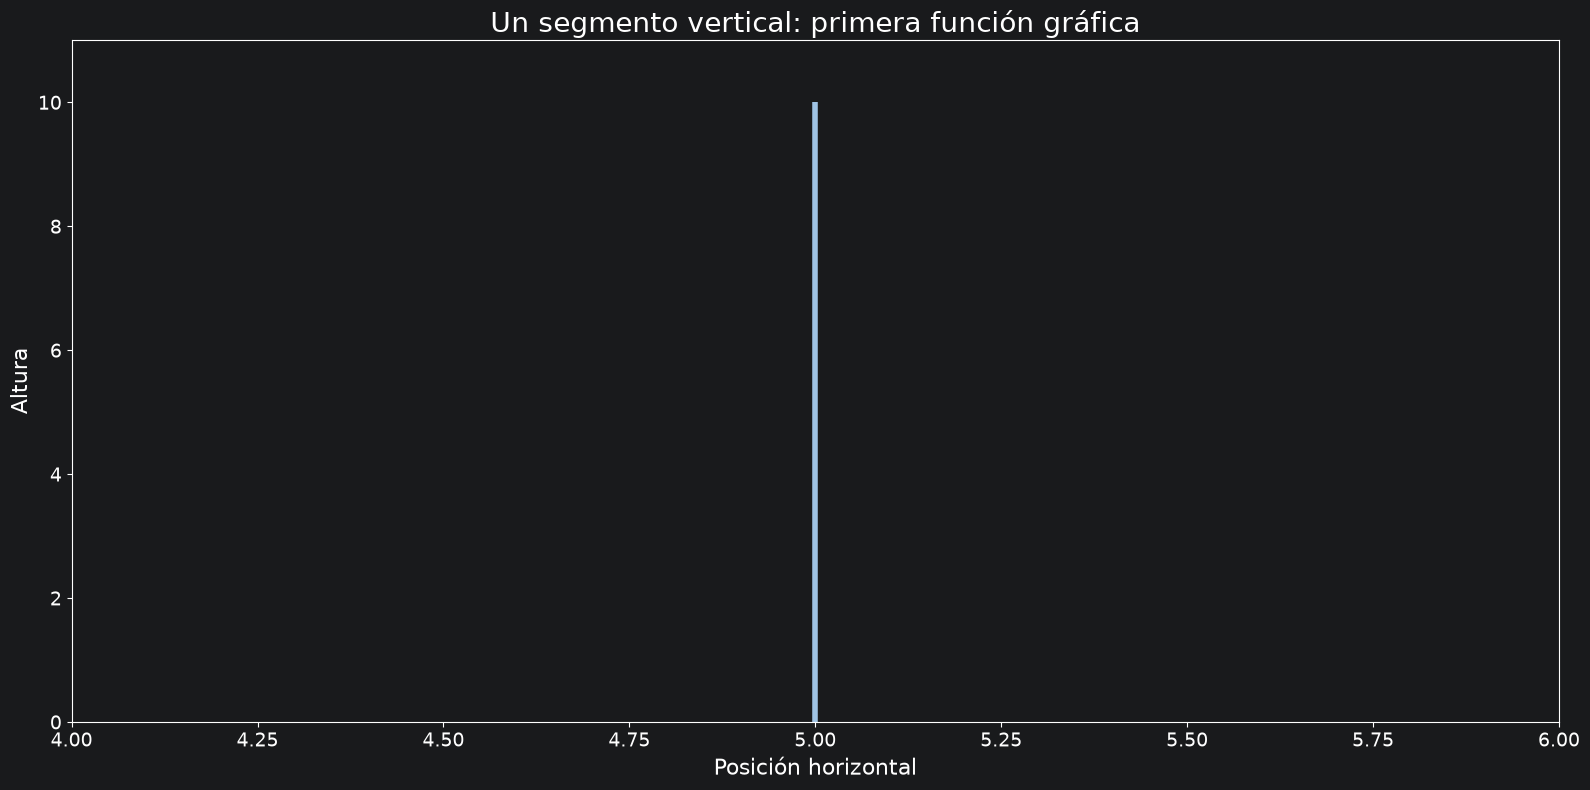

In [26]:
# Crea la figura y unos ejes amplios sobre los que dibujar.
fig, ax = plt.subplots(figsize=(16, 8))
# Traza en x=5 un segmento vertical desde y=0 hasta y=10.
_ = ax.vlines(x=5, ymin=0, ymax=10, color='#9fc3e4', linewidth=4)
# Acota ambos ejes para dejar espacio alrededor del segmento.
_ = ax.set(xlim=(4, 6), ylim=(0, 11))
# Añade un título descriptivo a la figura.
_ = ax.set_title('Un segmento vertical: primera función gráfica', fontsize=20)
# Identifica la coordenada horizontal.
_ = ax.set_xlabel('Posición horizontal', fontsize=16)
# Identifica la coordenada vertical.
_ = ax.set_ylabel('Altura', fontsize=16)
# Aumenta el tamaño de las cifras de los ejes.
ax.tick_params(labelsize=14)
# Ajusta los márgenes para que no se recorten las etiquetas.
fig.tight_layout()
# Presenta la figura terminada.
plt.show()

### Definir una función propia

`def cuadrado(x):` define una función que recibe un argumento `x`. La línea con sangría pertenece a la función, y `return` **devuelve** el cuadrado para que podamos reutilizarlo; definir la función no la ejecuta todavía.

$$
f(x)=x^2.
$$

Después de ejecutar la definición, `cuadrado(3)` sustituye $x$ por 3 y devuelve 9. Si eliminas `return`, Python ejecutará el cuerpo, pero una llamada no proporcionará ese resultado como valor de retorno.

In [27]:
# Define una función que recibe un número x y permite reutilizar su cálculo.
def cuadrado(x):
    # Devuelve x elevado a dos; la sangría sitúa esta instrucción dentro de la función.
    return x ** 2

In [28]:
# Llama a la función definida antes y calcula el cuadrado de 3.
cuadrado(3)

9

### Probar la función con varios argumentos

La celda siguiente llama a `cuadrado` con varios valores sin cambiar su definición. Compara entradas positivas y negativas: ambas producen un cuadrado no negativo, y las entradas opuestas dan el mismo resultado porque $(-x)^2=x^2$. Puedes cambiar los números de la tupla y ejecutar de nuevo la celda.

In [29]:
# Recorre tres entradas para comparar sus cuadrados sin redefinir la función.
for x in (3, -3, 0):
    # Calcula el cuadrado de la entrada actual y muestra la operación y su resultado.
    print(f'cuadrado({x}) = {cuadrado(x)}')

cuadrado(3) = 9
cuadrado(-3) = 9
cuadrado(0) = 0


### Ejercicio 1.1 — Ventas y beneficio

Una tienda vendió **15** productos el lunes, **22** el martes y **18** el miércoles. El precio de venta por unidad es **12 €** y el coste por unidad, **7 €**. Distingue siempre **unidades**, **ingresos** y **beneficio**, porque tienen interpretaciones y unidades distintas.

1. Guarda las ventas diarias en `lunes`, `martes` y `miercoles`.
2. Guarda el precio y el coste unitarios en variables distintas.
3. Obtén el total de productos vendidos.
4. Calcula las ventas medias por día.
5. Calcula los ingresos de los tres días.
6. Obtén el beneficio total después de restar los costes.
7. Define `beneficio(unidades)` para calcular el beneficio de **un día**.
8. Utiliza la función con las ventas del lunes y del martes por separado.

Para comprobar tus resultados, pregunta en cada paso si la cifra debe medirse en **productos**, **productos/día** o **euros**. Las celdas siguientes contienen únicamente pistas: escribe tú el código.

In [30]:
# 1.1.1 — Ventas de lunes, martes y miércoles.
# Crea las tres variables numéricas con las unidades vendidas cada día.
# Comprueba sus valores antes de pasar al siguiente apartado.

In [31]:
# 1.1.2 — Precio y coste de cada producto.
# Guarda el precio de venta y el coste unitario en dos variables distintas.
# ¿Cuál de los dos necesitarás restar al otro para calcular el beneficio por unidad?

In [32]:
# 1.1.3 — Total de productos vendidos.
# Combina las ventas de los tres días; todavía no intervienen el precio ni el coste.
# ¿Cuántos productos aporta cada día a ese total?

In [33]:
# 1.1.4 — Media de productos vendidos por día.
# Utiliza el total anterior y el número de días observados.
# ¿Tiene sentido que una media diaria se exprese en euros?

In [34]:
# 1.1.5 — Ingresos totales.
# Combina el total de unidades con el precio de venta por unidad.
# No confundas ingresos (euros cobrados) con beneficio (ingresos menos costes).

In [35]:
# 1.1.6 — Beneficio total de los tres días.
# Calcula el coste total de los productos vendidos y réstalo de los ingresos.
# También puedes razonar primero cuánto se gana por cada unidad vendida.

In [36]:
# 1.1.7 — Función beneficio(unidades).
# Define una función que reciba las unidades vendidas en un día y devuelva el beneficio de ese día.
# Reutiliza las variables precio y coste; recuerda la sangría y return.

In [37]:
# 1.1.8 — Beneficio del lunes y del martes.
# Llama a beneficio por separado con las unidades de cada uno de esos días.
# Comprueba que no estés pasando el precio o los ingresos como argumento.

## Tipos de objetos: vectores, matrices y tablas

Antes de analizar una muestra, debemos elegir cómo representarla. Un **vector** contiene una secuencia unidimensional de valores, una **matriz** organiza valores en filas y columnas y un **DataFrame** añade nombres y admite tipos diferentes por columna. También veremos **listas**, capaces de reunir objetos heterogéneos.

### Vectores de NumPy

`np.array` construye un vector a partir de valores explícitos; `np.arange(1, 6)` genera la sucesión de enteros del 1 al 5 porque el extremo superior se **excluye**. En los ejemplos, `v1` contiene edades numéricas, `v2` índices numéricos y `v3` letras. Los elementos de un array comparten un tipo (`dtype`), por lo que un vector de texto y uno numérico se operan de manera diferente. Ejecuta las tres celdas antes de probar sus índices.

In [38]:
# Guarda cinco edades como números decimales en un vector de NumPy.
v1 = np.array([32, 40, 61, 71, 39], dtype=float)  # Edades: valores numéricos
# Muestra el vector recién creado.
v1

array([32., 40., 61., 71., 39.])

In [39]:
# Genera enteros desde 1 hasta antes de 6 para obtener cinco posiciones.
v2 = np.arange(1, 6)  # Enteros del 1 al 5; el extremo final se excluye
# Muestra la sucesión creada.
v2

array([1, 2, 3, 4, 5])

In [40]:
# Construye un vector de cinco categorías representadas por letras.
v3 = np.array(["h", "m", "h", "m", "m"])  # Valores de texto
# Muestra sus categorías en orden.
v3

array(['h', 'm', 'h', 'm', 'm'], dtype='<U1')

#### Tipo del objeto frente a tipo de sus elementos

`type(v1)` identifica el objeto completo (un array de NumPy), mientras que `v1.dtype` describe cómo se almacenan **sus elementos**. Compara los tipos de `v1`, `v2` y `v3`: importa distinguir números con decimales, enteros y cadenas al calcular medias o filtrar valores. Una cadena que «parece un número» no es automáticamente una medida numérica.

In [41]:
# Identifica la clase del objeto completo v1 (un array).
type(v1)
# Examina el tipo de los valores numéricos almacenados en v1.
v1.dtype
# Examina el tipo entero de los elementos de v2.
v2.dtype
# Examina el tipo de texto de los elementos de v3.
v3.dtype

numpy.ndarray

dtype('float64')

dtype('int64')

dtype('<U1')

#### Acceso y modificación de un vector

**Los índices comienzan en cero**: el tercer valor ocupa la posición `2`. Para seleccionar varios valores usamos `inicio:fin`, donde `fin` no se incluye; por ejemplo, `v1[1:4]` devuelve las posiciones 1, 2 y 3. Si las posiciones no son contiguas, pasamos una lista como `v1[[0, 1, 3]]`.

La lectura `v1[2]` no cambia el vector. En cambio, `v1[2] = 62` **modifica el objeto** y los accesos posteriores encontrarán el nuevo valor. Ejecuta las celdas en orden y fíjate en la diferencia entre consultar, asignar y seleccionar varios elementos.

In [42]:
# Consulta la tercera edad: las posiciones del vector empiezan en cero.
v1[2]  # Tercer elemento

np.float64(61.0)

**Modificar un elemento.** El acceso anterior solo consultaba un valor. Ahora sustituimos el tercero por 62; vuelve a consultar `v1` si quieres comprobar que el cambio permanece en el kernel.

In [43]:
# Sustituye por 62 la edad situada en la tercera posición del vector.
v1[2] = 62
# Comprueba el nuevo valor sin modificarlo de nuevo.
v1[2]

np.float64(62.0)

**Seleccionar varios elementos.** Un intervalo como `[1:4]` toma posiciones contiguas sin incluir la última; una lista de índices como `[[0, 1, 3]]` permite saltar posiciones. Ambas consultas reflejarán el nuevo valor de `v1` si la selección lo contiene.

In [44]:
# Selecciona las posiciones 1, 2 y 3; el extremo 4 queda excluido.
v1[1:4]       # Elementos del segundo al cuarto
# Selecciona posiciones concretas aunque no sean contiguas.
v1[[0, 1, 3]]  # Elementos primero, segundo y cuarto

array([40., 62., 71.])

array([32., 40., 71.])

### Matrices

Una matriz es un array de **dos dimensiones**: cada entrada se identifica por una fila y una columna. `m1` se construye con dos filas explícitas, mientras que `np.column_stack((v1, v2))` coloca los vectores como dos **columnas** de `m2`. Ambos vectores deben tener el mismo número de elementos para que las filas queden alineadas.

En una matriz de forma $(r,c)$ hay $r$ filas y $c$ columnas. Todavía no hemos asignado etiquetas: para consultar una entrada utilizaremos índices numéricos, y después convertiremos `m2` en un DataFrame con nombres de filas y columnas.

In [45]:
# Crea una matriz de dos filas y dos columnas a partir de listas anidadas.
m1 = np.array([[10, 20], [30, 40]])
# Muestra la disposición de los cuatro valores.
m1

array([[10, 20],
       [30, 40]])

In [46]:
# Alinea v1 y v2 por posición como dos columnas de una matriz.
m2 = np.column_stack((v1, v2))  # Para apilar filas: np.vstack((v1, v2))
# Muestra las filas emparejadas de ambas columnas.
m2

array([[32.,  1.],
       [40.,  2.],
       [62.,  3.],
       [71.,  4.],
       [39.,  5.]])

#### Acceso y modificación de matrices

En `m1[fila, columna]`, el primer índice indica **qué fila** y el segundo **qué columna**; ambos empiezan en cero. `m1[1, 0]` selecciona una entrada, `m1[1, :]` la segunda fila completa y `m1[:, 0]` la primera columna completa. El signo `:` significa «todas las posiciones» de esa dimensión.

Tras consultar las tres posibilidades, asigna un valor a `m1[1, 0]` y vuelve a mostrar la matriz. Comprueba que solo cambia esa celda: seleccionar un valor y **modificar** un objeto son operaciones diferentes.

In [47]:
# Consulta el valor de la segunda fila y la primera columna.
m1[1, 0]  # Segunda fila, primera columna
# Selecciona toda la segunda fila con «:» en las columnas.
m1[1, :]  # Segunda fila
# Selecciona toda la primera columna con «:» en las filas.
m1[:, 0]  # Primera columna

np.int64(30)

array([30, 40])

array([10, 30])

**Cambiar una sola entrada.** La asignación usa los mismos dos índices que la consulta. Mostrar `m1` después permite verificar qué fila y qué columna se han modificado.

In [48]:
# Cambia únicamente la entrada de la segunda fila y primera columna.
m1[1, 0] = 35
# Muestra la matriz para verificar la modificación.
m1

array([[10, 20],
       [35, 40]])

#### De matriz a DataFrame

`pd.DataFrame(m2)` conserva los valores numéricos de la matriz y añade un **índice de filas** y **nombres de columnas**. Aquí llamamos `edad` y `orden` a las columnas; las cinco primeras letras de `letters` identifican las filas. Estas etiquetas ayudan a leer una tabla y permiten consultar después las columnas por su nombre, no solo por su posición.

Compara `m2.columns`, `m2.index` y la tabla completa. El nombre `m2` pasa a referirse al DataFrame recién creado: ya no apunta a la matriz sin etiquetas que había antes.

In [49]:
# Transforma la matriz en una tabla con índices y columnas etiquetables.
m2 = pd.DataFrame(m2)
# Asigna nombres descriptivos a las dos columnas de la tabla.
m2.columns = ["edad", "orden"]
# Usa las primeras cinco letras como etiquetas de las filas.
m2.index = letters[:5]

# Muestra los nombres de las columnas.
m2.columns
# Muestra las etiquetas de las filas.
m2.index
# Presenta la tabla completa con sus datos y etiquetas.
m2

Index(['edad', 'orden'], dtype='str')

Index(['a', 'b', 'c', 'd', 'e'], dtype='str')

,edad,orden
a,32.0,1.0
b,40.0,2.0
c,62.0,3.0
d,71.0,4.0
e,39.0,5.0


### DataFrames

Un DataFrame de pandas es una tabla cuyas columnas tienen la **misma longitud** pero pueden almacenar tipos distintos: por ejemplo, una columna de letras y otra de números. Cada fila tiene un índice y cada columna un nombre. En los ejemplos, `df1` combina letras con una secuencia numérica y `df2` combina las letras de `v3` con las edades de `v1`.

Ejecuta cada creación y observa la tabla debajo de la celda. La vista **Variables** de VS Code ofrece un visor de datos adicional, pero no modifica la tabla ni sustituye a comprobar el índice, las columnas y los tipos cuando diseñes un análisis.

In [50]:
# Crea una tabla con diez letras y los enteros del 1 al 10 como columnas.
df1 = pd.DataFrame({"x": letters[:10], "y": np.arange(1, 11)})
# Muestra las diez filas resultantes.
df1

,x,y
0,a,1
1,b,2
2,c,3
3,d,4
4,e,5
5,f,6
6,g,7
7,h,8
8,i,9
9,j,10


In [51]:
# Combina el vector de categorías y el de edades en dos columnas de una tabla.
df2 = pd.DataFrame({"v3": v3, "v1": v1})
# Muestra los cinco registros y sus respectivos tipos de valores.
df2

,v3,v1
0,h,32.0
1,m,40.0
2,h,62.0
3,m,71.0
4,m,39.0


#### Acceso y modificación de tablas

Hay dos formas principales de acceder a las celdas: `iloc` usa **posiciones enteras** y `loc` usa **etiquetas** o condiciones. `df1['x']` selecciona una columna por nombre; `df1.iloc[:, 0]` selecciona su posición. `df1.x` es un atajo cuando el nombre no entra en conflicto con otro atributo, pero los corchetes son más fiables.

Primero **lee** una columna, una celda y una fila. Después cambia `df1.iloc[1, 1]` y `df1.iloc[2, 0]` en celdas separadas. La segunda lectura de `df1` revela la modificación anterior: al contrario que seleccionar, **asignar** cambia la tabla guardada en memoria. Recuerda que los índices de posición empiezan en cero.

In [52]:
# Recupera la columna cuyo nombre es «x».
df1["x"]       # Columna llamada x
# Consulta la misma columna como atributo cuando su nombre lo permite.
df1.x          # Acceso por atributo, cuando el nombre de la columna lo permite
# Selecciona esa primera columna mediante su posición cero.
df1.iloc[:, 0]  # Primera columna por posición

0    a
1    b
2    c
3    d
4    e
5    f
6    g
7    h
8    i
9    j
Name: x, dtype: str

0    a
1    b
2    c
3    d
4    e
5    f
6    g
7    h
8    i
9    j
Name: x, dtype: str

0    a
1    b
2    c
3    d
4    e
5    f
6    g
7    h
8    i
9    j
Name: x, dtype: str

In [53]:
# Consulta una celda indicando primero la fila y luego la columna por posición.
df1.iloc[1, 0]       # Segunda fila, primera columna
# Obtiene la misma celda seleccionando la columna «x» antes de la fila.
df1["x"].iloc[1]    # El mismo elemento, seleccionando primero la columna

'b'

'b'

In [54]:
# Lee la segunda fila completa: «:» incluye todas sus columnas.
df1.iloc[1, :]  # Segunda fila

x    b
y    2
Name: 1, dtype: object

**Modificar valores por posición.** La siguiente celda cambia la segunda fila de la columna numérica. Lee primero el resultado de la consulta anterior y después verifica el valor nuevo en `df1`.

In [55]:
# Sustituye por 35 el número de la segunda fila, segunda columna.
df1.iloc[1, 1] = 35
# Muestra la tabla para comprobar el cambio en la columna numérica.
df1

,x,y
0,a,1
1,b,35
2,c,3
3,d,4
4,e,5
5,f,6
6,g,7
7,h,8
8,i,9
9,j,10


**Modificar otra columna.** Sustituimos ahora una letra de la columna `x`. Las asignaciones son independientes: esta no debe deshacer el cambio anterior en la columna `y`.

In [56]:
# Cambia por «H» la letra de la tercera fila, primera columna.
df1.iloc[2, 0] = "H"
# Presenta la tabla y permite verificar que se conserva el cambio anterior.
df1

,x,y
0,a,1
1,b,35
2,H,3
3,d,4
4,e,5
5,f,6
6,g,7
7,h,8
8,i,9
9,j,10


#### Búsqueda de observaciones y valores extremos

Una condición como `df1['x'] == 'e'` compara cada fila con la letra buscada y produce una **máscara booleana**. `np.flatnonzero` transforma esa máscara en **posiciones**; `df1.loc[mascara]` recupera las **filas completas**. Son respuestas distintas a «¿dónde está?» y «¿qué observaciones cumplen la condición?».

Para una columna numérica, `idxmax()` e `idxmin()` devuelven las **etiquetas de fila** del máximo y del mínimo, no los propios valores; `max()` devuelve el máximo. En la última celda se muestra la fila que alcanza ese máximo. Si hubiera empates, `idxmax()` escogería la primera etiqueta encontrada, mientras que una máscara `== max()` podría mostrar varias filas.

In [57]:
# Compara cada letra con «e» y obtiene las posiciones donde la condición es cierta.
np.flatnonzero(df1["x"] == "e")  # Posiciones que cumplen la condición

array([4])

In [58]:
# Obtiene la etiqueta de la primera fila que alcanza el máximo de «y».
df1["y"].idxmax()  # Etiqueta de la fila con el valor máximo
# Obtiene la etiqueta de la primera fila que alcanza el mínimo de «y».
df1["y"].idxmin()  # Etiqueta de la fila con el valor mínimo

1

0

In [59]:
# Filtra las filas completas cuya letra en «x» coincide con «e».
df1.loc[df1["x"] == "e"]
# Calcula el máximo de «y» y muestra todas las filas que lo alcanzan.
df1.loc[df1["y"] == df1["y"].max()]

,x,y
4,e,5


,x,y
1,b,35


### Listas: reunir objetos de distintos tipos

A diferencia de un array numérico, una **lista de Python** puede contener un vector (`v1`), una matriz (`m1`) y una tabla (`df1`) como elementos diferentes. `l1 = [v1, m1, df1]` crea esa colección sin combinar sus valores ni exigirles la misma forma.

Cada elemento conserva su identidad: la lista es el contenedor, mientras que `l1[0]` sigue siendo el vector original. Más adelante distinguimos entre acceder a un elemento y obtener una **sublista** mediante un intervalo.

In [60]:
# Agrupa un vector, una matriz y una tabla como tres elementos de una lista.
l1 = [v1, m1, df1]
# Muestra los objetos conservando el tipo de cada uno.
l1

[array([32., 40., 62., 71., 39.]),
 array([[10, 20],
        [35, 40]]),
    x   y
 0  a   1
 1  b  35
 2  H   3
 3  d   4
 4  e   5
 5  f   6
 6  g   7
 7  h   8
 8  i   9
 9  j  10]

#### Selección y cambios en una lista

En una lista, `l1[:1]` devuelve **otra lista** que contiene su primer elemento, mientras que `l1[0]` devuelve directamente el elemento. Compara los resultados de `type(...)` para verificarlo.

Con `append` añadimos un cuarto elemento al final. Después `l1[3] = 4` sustituye **ese mismo cuarto elemento** sin cambiar el tamaño de la lista. Ejecuta la incorporación antes de la sustitución: si la posición 3 aún no existe, no puedes asignarle un valor mediante indexación.

In [61]:
# Obtiene una sublista que contiene solo el primer elemento.
l1[:1]
# Comprueba que el resultado del intervalo sigue siendo una lista.
type(l1[:1])

[array([32., 40., 62., 71., 39.])]

list

In [62]:
# Extrae directamente el primer objeto guardado en la lista.
l1[0]
# Comprueba que conserva su tipo de array, en lugar de ser una sublista.
type(l1[0])

array([32., 40., 62., 71., 39.])

numpy.ndarray

In [63]:
# Crea una secuencia del 1 al 10 y la incorpora como cuarto elemento.
l1.append(np.arange(1, 11))  # Añadir un cuarto elemento
# Muestra la lista ampliada para comprobar su longitud y contenido.
l1

[array([32., 40., 62., 71., 39.]),
 array([[10, 20],
        [35, 40]]),
    x   y
 0  a   1
 1  b  35
 2  H   3
 3  d   4
 4  e   5
 5  f   6
 6  g   7
 7  h   8
 8  i   9
 9  j  10,
 array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10])]

In [64]:
# Sustituye el cuarto objeto existente por el número 4, sin añadir otro elemento.
l1[3] = 4  # Sustituir el cuarto elemento
# Muestra el resultado de esa sustitución.
l1

[array([32., 40., 62., 71., 39.]),
 array([[10, 20],
        [35, 40]]),
    x   y
 0  a   1
 1  b  35
 2  H   3
 3  d   4
 4  e   5
 5  f   6
 6  g   7
 7  h   8
 8  i   9
 9  j  10,
 4]

### Ejercicio 1.2 — Construir y actualizar una tabla

Organiza las siguientes observaciones en un DataFrame con las columnas **marca**, **modelo** y **consumo**. A diferencia de un array de un solo tipo, la tabla debe contener texto en las dos primeras columnas y números en la tercera.

| marca | modelo | consumo |
| :--- | :--- | ---: |
| audi | A3 | 6.8 |
| Volkswagen | Polo | 6.8 |
| bmw | X5 | 12.5 |
| renault | megane | 4.7 |
| fiat | punto | 5.0 |

1. Construye la tabla y comprueba sus columnas y tipos.
2. Cambia **solo** el consumo del `fiat` `punto` a **4.5**. Busca la fila por ambas etiquetas, no por su posición: si el orden de las filas cambiase, una selección por posición podría modificar otro coche.

Las celdas de código contienen pistas, no la solución.

In [65]:
# 1.2.1 — Construcción de la tabla de coches.
# Crea un DataFrame con las columnas marca, modelo y consumo siguiendo la tabla del enunciado.
# Comprueba cuántas filas tiene y qué tipo de datos presenta cada columna.

In [66]:
# 1.2.2 — Actualizar el consumo del fiat punto.
# Localiza la fila combinando la marca y el modelo; evita depender de su posición.
# Utiliza .loc para cambiar solo el valor de consumo y verifica el resultado.

## Instrucciones útiles para programar

### Condiciones y bucles

Un bloque `if` ejecuta su contenido **solo si** la condición es verdadera: en el ejemplo se comprueba la edad del primer elemento de `v1`. Un bloque `for` repite una operación para cada valor de `range(5)`, es decir, para las posiciones 0, 1, 2, 3 y 4. La sangría delimita qué instrucciones pertenecen a cada bloque.

Estas celdas usan `v1`, creado anteriormente. Si las ejecutas tras reiniciar el kernel sin volver a crear el vector, fallarán; esta dependencia es una forma práctica de entender cómo se conserva el estado del cuaderno.

In [67]:
# Comprueba si la primera edad de v1 es 32 antes de mostrar el mensaje.
if v1[0] == 32:
    # Muestra el mensaje solo cuando se cumple la condición anterior.
    print("La edad del primer individuo es 32")

La edad del primer individuo es 32


In [68]:
# Recorre las cinco primeras posiciones, desde 0 hasta 4.
for i in range(5):
    # Muestra el valor de v1 situado en la posición actual.
    print(v1[i])

32.0
40.0
62.0
71.0
39.0


### Gestionar el espacio de trabajo

`%whos` lista los nombres definidos durante la sesión y ayuda a localizar variables que aún permanecen en memoria. El panel **Variables** de VS Code muestra una vista interactiva; ninguna de estas inspecciones altera los objetos.

`sys.getsizeof(v1)` informa del **tamaño superficial del objeto en bytes**, no de toda la memoria usada por objetos a los que pudiera hacer referencia. `del v1` elimina después ese **nombre** del espacio de variables. Esta última operación no borra por sí misma los ficheros ni los datos de otras variables, pero un acceso posterior a `v1` fallará si ya no existe.

In [69]:
# Lista las variables disponibles en la sesión de IPython.
%whos

Variable     Type         Data/Info
-----------------------------------
LETTERS      ndarray      26: 26 elems, type `<U1`, 104 bytes
Path         type         <class 'pathlib.Path'>
ax           Axes         Axes(0.0478852,0.091326;0.929615x0.852007)
calendar     module       <module 'calendar' from '<...>/python3.12/calendar.py'>
csv          module       <module 'csv' from '/usr/lib/python3.12/csv.py'>
cuadrado     function     <function cuadrado at 0x7a8427297ba0>
debugpy      module       <module 'debugpy' from '/<...>ers/debugpy/__init__.py'>
df1          DataFrame    Shape: (10, 2)
df2          DataFrame    Shape: (5, 2)
display      function     <function display at 0x7a84b2f49ee0>
fig          Figure       Figure(1600x800)
i            int          4
l1           list         n=4
letters      ndarray      26: 26 elems, type `<U1`, 104 bytes
m1           ndarray      2x2: 4 elems, type `int64`, 32 bytes
m2           DataFrame    Shape: (5, 2)
math         module       <module '

In [70]:
# Consulta cuántos bytes ocupa directamente v1, sin sumar los objetos a los que apunta.
sys.getsizeof(v1)  # Tamaño superficial del objeto en bytes; no mide todo lo que referencia.

152

In [71]:
# Quita el nombre v1 de las variables disponibles en esta sesión.
del v1  # Eliminar una variable de la sesión

### Reiniciar las variables de la sesión

`%reset -f` **vacía el espacio de nombres** de IPython: se perderán las variables y también los nombres importados como `np` y `pd`. A diferencia de `del v1`, este paso elimina todos los nombres de usuario del kernel. **No elimina los archivos del proyecto ni el contenido de las celdas.**

Ejecuta el reinicio solo después de terminar los ejemplos anteriores. La celda inmediatamente posterior vuelve a importar las bibliotecas y deja preparado el cuaderno para leer datos; si saltas esas importaciones, la sección siguiente no tendrá disponibles sus funciones.

In [72]:
# Borra las variables y los nombres importados del espacio de trabajo de IPython.
%reset -f

In [73]:
# Recupera las funciones del calendario tras el reinicio.
import calendar
# Permite configurar cómo se escriben los archivos CSV.
import csv
# Proporciona operaciones matemáticas.
import math
# Ofrece constantes y utilidades para trabajar con texto.
import string
# Da acceso a información y funciones del intérprete.
import sys
# Permite construir y comprobar rutas de archivos.
from pathlib import Path

# Importa NumPy para trabajar con arrays y cálculos numéricos.
import numpy as np
# Importa pandas para leer y analizar tablas.
import pandas as pd
# Importa las funciones de creación de gráficos.
import matplotlib.pyplot as plt
# Permite mostrar tablas explícitamente en el cuaderno.
from IPython.display import display
# Importa la función para dibujar diagramas de mosaico.
from statsmodels.graphics.mosaicplot import mosaic

## Lectura de datos

Hasta aquí los ejemplos se crearon dentro de Python; ahora trabajaremos con un **fichero externo**. Separaremos tres pasos: localizar la carpeta, interpretar correctamente el contenido y verificar el resultado. Una lectura incorrecta puede dejar toda una fila en una sola columna o confundir texto con números; en ese caso, cualquier estadístico posterior sería poco fiable.

### Encontrar la carpeta de datos

El bucle busca la carpeta `datos` subiendo desde la carpeta de trabajo actual, tanto si abres el cuaderno desde la raíz del proyecto como desde `sesiones/sesion1`. Si encuentra el fichero esperado, guarda esa ruta en `DATA_PATH`; si no, muestra un error explícito. Usaremos la misma ruta para los ejemplos y los ejercicios posteriores.

In [74]:
# Busca el archivo de móviles en la carpeta actual y en cada carpeta superior.
for carpeta in (Path.cwd(), *Path.cwd().parents):
    # Comprueba si esta carpeta contiene el archivo esperado dentro de datos.
    if (carpeta / "datos" / "Mobiles.txt").is_file():
        # Guarda la ruta de la carpeta de datos para las lecturas posteriores.
        DATA_PATH = carpeta / "datos"
        # Detiene la búsqueda al encontrar el archivo.
        break
# Este bloque se ejecuta solo si el bucle termina sin encontrar el archivo.
else:
    # Informa claramente de que el cuaderno no se abrió desde el proyecto.
    raise FileNotFoundError("Abre el notebook dentro de la carpeta LaSalle_Estadistica.")

### Primera lectura: separadores y tipos

El fichero de móviles incluye una **fila de cabecera** y columnas separadas por `;`; los números usan el **punto decimal**. `pd.read_csv` interpreta esas reglas con `sep=';'` y `decimal='.'`. En esta primera lectura consideramos ausente el texto `NA`, pero **todavía no** los campos vacíos: el objetivo es comparar más adelante las dos interpretaciones.

Las columnas de texto se convierten en `category` para reflejar que representan grupos, no magnitudes numéricas. `keep_default_na=False` impide que pandas añada sin avisar otros marcadores de ausencia a los que hemos elegido; comprueba después la forma y los primeros registros antes de calcular estadísticas.

In [75]:
# Lee el archivo separado por punto y coma, con punto decimal y solo 'NA' como ausente.
datos = pd.read_csv(
    DATA_PATH / 'Mobiles.txt',
    sep=';', decimal='.', na_values=['NA'], keep_default_na=False,
)
# Recorre las columnas de texto detectadas en la tabla recién cargada.
for columna in datos.select_dtypes(include=['object', 'str']):
    # Convierte cada columna de texto en una variable categórica.
    datos[columna] = datos[columna].astype('category')

### Inspección de la primera lectura

**Primero**, `datos.shape` indica cuántas filas y columnas se han leído: una dimensión inesperada es la primera señal de un separador mal elegido. **Después**, `datos.head()` permite reconocer la cabecera, el aspecto de las categorías y si las columnas numéricas tienen valores razonables. **Por último**, `describe(include='all')` resume medidas numéricas y categorías.

No interpretes todavía los estadísticos como definitivos: en la lectura inicial los campos vacíos pueden estar representados de forma distinta a los `NA`. Fíjate en `count` de cada columna y compara ese número con el total de filas antes de decidir qué observaciones son válidas.

In [76]:
# Consulta la pareja (número de filas, número de columnas) de la tabla.
datos.shape  # Número de filas y columnas

(179, 10)

In [77]:
# Muestra los primeros registros para comprobar cómo se han leído las columnas.
datos.head()  # Primeras filas

,Gender,Age,Faculty,Brand,Colour,Provider,PlanType,Bill,PrimaryUse,No.Phones
0,Female,17,Arts,LG,Silver,Telstra,Plan,70.0,SMS,1
1,Male,21,Arts,Motorola,Silver,Overseas,Prepaid,200.0,Calls,3
2,Female,20,Arts,Samsung,Silver,Optus,Prepaid,30.0,Both,1
3,Male,23,Arts,,,,,NaN,,2
4,Female,38,Arts,Nokia,Blue,Optus,Plan,120.0,Calls,3


In [78]:
# Resume tanto las columnas numéricas como las categóricas de la tabla.
datos.describe(include="all")  # Descriptiva de todas las columnas

,Gender,Age,Faculty,Brand,Colour,Provider,PlanType,Bill,PrimaryUse,No.Phones
count,179,179.000000,179,179,179,179,179,174.000000,179,179.000000
unique,2,NaN,10,15,13,7,3,NaN,4,NaN
top,Male,NaN,Business,Nokia,Silver,Optus,Prepaid,NaN,Both,NaN
freq,96,NaN,68,104,49,98,98,NaN,68,NaN
mean,NaN,22.217877,NaN,NaN,NaN,NaN,NaN,46.850575,NaN,2.385475
std,NaN,6.366389,NaN,NaN,NaN,NaN,NaN,41.577570,NaN,1.848781
min,NaN,17.000000,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000
25%,NaN,18.000000,NaN,NaN,NaN,NaN,NaN,25.000000,NaN,1.000000
50%,NaN,20.000000,NaN,NaN,NaN,NaN,NaN,35.000000,NaN,2.000000
75%,NaN,24.000000,NaN,NaN,NaN,NaN,NaN,60.000000,NaN,3.000000


### Segunda lectura: reconocer los valores ausentes

El fichero también contiene campos vacíos sin el texto `NA`. Repetimos la lectura con **ambos marcadores**, `na_values=['NA', '']`, y así pandas los interpreta como observaciones desconocidas, no como categorías ni como ceros. `keep_default_na=False` deja documentada nuestra decisión sobre el tratamiento de ausencias.

Al convertir de nuevo las columnas textuales en `category`, recuerda que `datos` **sustituye** la tabla cargada en la primera lectura. Compara las estadísticas antes y después: si cambia `count` o el tipo de una columna, la diferencia puede proceder de los campos vacíos, no de nuevos datos.

In [79]:
# Vuelve a leer el archivo: ahora trata 'NA' y los campos vacíos como ausentes.
datos = pd.read_csv(
    DATA_PATH / 'Mobiles.txt',
    sep=';', decimal='.', na_values=['NA', ''], keep_default_na=False,
)
# Recorre las columnas de texto de la nueva versión de la tabla.
for columna in datos.select_dtypes(include=['object', 'str']):
    # Convierte su texto en categorías sin modificar las columnas numéricas.
    datos[columna] = datos[columna].astype('category')

#### Comprobar la nueva lectura

En `describe(include='all')`, la fila `count` indica **cuántos valores conocidos** tiene cada columna. Para una variable numérica verás centro, dispersión y cuartiles; para una categórica, número de categorías (`unique`), categoría más frecuente (`top`) y su frecuencia (`freq`). Los apartados que no tienen sentido para ese tipo de dato aparecen vacíos en la tabla.

Compara `count` de `Brand` y `Bill` con el número de filas: una fila puede conservar información de edad aunque no tenga marca o factura. En la siguiente celda calculamos por separado cuántos valores faltan en cada columna.

In [80]:
# Muestra el recuento de valores válidos y las estadísticas de cada tipo de columna.
datos.describe(include='all')  # Recuento de casos válidos y resumen de cada columna.

,Gender,Age,Faculty,Brand,Colour,Provider,PlanType,Bill,PrimaryUse,No.Phones
count,179,179.000000,179,174,174,174,174,174.000000,174,179.000000
unique,2,NaN,10,14,12,6,2,NaN,3,NaN
top,Male,NaN,Business,Nokia,Silver,Optus,Prepaid,NaN,Both,NaN
freq,96,NaN,68,104,49,98,98,NaN,68,NaN
mean,NaN,22.217877,NaN,NaN,NaN,NaN,NaN,46.850575,NaN,2.385475
std,NaN,6.366389,NaN,NaN,NaN,NaN,NaN,41.577570,NaN,1.848781
min,NaN,17.000000,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000
25%,NaN,18.000000,NaN,NaN,NaN,NaN,NaN,25.000000,NaN,1.000000
50%,NaN,20.000000,NaN,NaN,NaN,NaN,NaN,35.000000,NaN,2.000000
75%,NaN,24.000000,NaN,NaN,NaN,NaN,NaN,60.000000,NaN,3.000000


#### Recuento de ausentes por columna

`datos.isna()` devuelve una condición por celda: **verdadero** si el valor está ausente. Al aplicar `.sum()` a cada columna contamos los verdaderos. Si $n$ es el número de filas, para cada variable debe cumplirse:

$$
n_{\text{válidos}}+n_{\text{ausentes}}=n.
$$

Esta identidad permite contrastar el recuento con la fila `count` anterior. Excluir valores ausentes cambia el **denominador** de una media o de una proporción; sustituirlos por cero, en cambio, sería inventar observaciones que no aparecen en el fichero.

In [81]:
# Detecta los valores ausentes y suma cuántos hay en cada columna.
datos.isna().sum()  # Valores ausentes de cada variable.

Gender        0
Age           0
Faculty       0
Brand         5
Colour        5
Provider      5
PlanType      5
Bill          5
PrimaryUse    5
No.Phones     0
dtype: int64

### Explorar los datos sin modificarlos

La función `explorar_moviles(marca, filas)` ofrece una **vista**: con «Todas», muestra las primeras filas de la tabla; con una marca, filtra por `Brand` y después limita el número de filas. El mensaje indica cuántas observaciones cumplen el filtro antes de recortar la presentación con `head(filas)`.

La primera celda **define** la función y la segunda la llama con valores concretos. Cambia `marca` o `filas` y ejecuta de nuevo la llamada: la consulta no elimina observaciones de `datos`. Compara «filas que cumplen el filtro» con «filas mostradas» cuando el límite sea pequeño.

In [82]:
# Define una consulta reutilizable que muestra móviles de una marca concreta o todas.
def explorar_moviles(marca, filas):
    # Selecciona toda la tabla o solo las filas cuya marca coincide con la solicitada.
    vista = datos if marca == "Todas" else datos.loc[datos["Brand"] == marca]
    # Indica el total de filas seleccionadas y el máximo que se mostrará.
    print(f"{len(vista)} observaciones; mostrando hasta {filas} filas.")
    # Presenta únicamente las primeras filas solicitadas de la selección.
    display(vista.head(filas))

In [83]:
# Muestra hasta diez filas de todas las marcas usando la función recién definida.
explorar_moviles(marca='Todas', filas=10)
# Prueba también explorar_moviles(marca='Nokia', filas=5).

179 observaciones; mostrando hasta 10 filas.


,Gender,Age,Faculty,Brand,Colour,Provider,PlanType,Bill,PrimaryUse,No.Phones
0,Female,17,Arts,LG,Silver,Telstra,Plan,70.0,SMS,1
1,Male,21,Arts,Motorola,Silver,Overseas,Prepaid,200.0,Calls,3
2,Female,20,Arts,Samsung,Silver,Optus,Prepaid,30.0,Both,1
3,Male,23,Arts,NaN,NaN,NaN,NaN,NaN,NaN,2
4,Female,38,Arts,Nokia,Blue,Optus,Plan,120.0,Calls,3
5,Male,19,Built Env,Ericsson,Blue,Vodafone,Prepaid,10.0,Both,1
6,Male,23,Built Env,Ericsson,Black,Telstra,Plan,100.0,Both,1
7,Male,24,Built Env,Ericsson,Silver,Optus,Plan,30.0,Calls,9
8,Male,19,Built Env,Motorola,Blue,Vodafone,Prepaid,20.0,SMS,1
9,Male,19,Built Env,Motorola,Grey,Telstra,Plan,43.0,Calls,4


### Ejercicio 1.3 — Leer e inspeccionar vuelos

Ahora te corresponde aplicar a otro fichero el mismo proceso: **identificar el separador**, **leer**, **inspeccionar** y **filtrar**. El archivo está en `DATA_PATH / 'flights.txt'`; observa sus primeras filas y cómo se señalan los valores ausentes antes de elegir los parámetros de `pd.read_csv`.

1. Lee la tabla en `datos2` y confirma que sus columnas tienen nombres independientes.
2. Comprueba sus dimensiones, muestra algunas filas y realiza una descriptiva general. Identifica qué variables son numéricas y cuáles categóricas.
3. Localiza el vuelo **251** cuya matrícula es **N855UA** y consulta su `air_time` (**minutos de vuelo efectivo**, no hora de llegada). Combina **las dos condiciones** para evitar elegir otro vuelo.

Trabaja en las tres celdas de pistas sin incluir la solución en el enunciado; conserva `datos2` para los ejercicios siguientes.

In [84]:
# 1.3.1 — Lectura de vuelos.
# Busca flights.txt en DATA_PATH y examina qué separa sus columnas y cómo marca los ausentes.
# Lee la tabla con pandas y asígnala a datos2 para reutilizarla en los ejercicios siguientes.
# Comprueba los nombres de las columnas antes de empezar a filtrar.

In [85]:
# 1.3.2 — Inspección de datos2.
# Muestra el número de filas y columnas, algunas filas y una descriptiva global.
# ¿Qué columnas son numéricas y en cuáles aparecen valores ausentes?

In [86]:
# 1.3.3 — Duración del vuelo indicado.
# Filtra simultáneamente por el número de vuelo 251 y la matrícula N855UA.
# Comprueba cuántas filas coinciden antes de consultar la columna air_time.
# No confundas el tiempo en el aire con el retraso ni con la hora de llegada.

## Escritura de datos a un fichero

### Guardar la tabla de móviles

Leer un fichero crea una tabla en memoria; **exportarlo** produce un archivo persistente. Definimos `OUTPUT_PATH` dentro de `sesiones/sesion1/salidas` y creamos la carpeta si no existe. `to_csv` controla el formato de salida: `sep='\t'` separa columnas mediante **tabuladores**, `index=False` evita escribir el índice, `quoting=csv.QUOTE_NONE` evita comillas alrededor de categorías y `na_rep='NA'` indica cómo escribir un dato ausente.

En este ejemplo mantenemos la cabecera porque no usamos `header=False`. Abrir el fichero exportado y comprobar separadores, encabezado y ausentes es tan importante como comprobar un resultado numérico. Estas celdas son ejemplos resueltos; el ejercicio de vuelos posterior debe hacerse por tu cuenta.

In [87]:
# Construye la ruta donde se guardarán los archivos generados.
OUTPUT_PATH = DATA_PATH.parent / "sesiones" / "sesion1" / "salidas"
# Crea la carpeta de salida si todavía no existe, junto con sus carpetas superiores.
OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

# Guarda todos los móviles en un archivo tabulado, sin índice ni comillas y con 'NA' para ausentes.
datos.to_csv(
    OUTPUT_PATH / "Mobiles_test.txt",
    sep="\t", index=False, quoting=csv.QUOTE_NONE, na_rep="NA",
)

### Guardar solo una selección

El filtro por `Brand == 'Nokia'` selecciona un **subconjunto de filas** sin modificar la tabla completa. Lo exportamos a otro fichero con el mismo separador, sin índice y con la misma representación de los ausentes.

Contrasta el número de registros exportados con el número de observaciones Nokia en la tabla original: exportar un subconjunto no significa reemplazar `datos` en memoria.

In [88]:
# Filtra solo los móviles Nokia y los guarda en otro archivo tabulado sin índice ni comillas.
datos.loc[datos["Brand"] == "Nokia"].to_csv(
    OUTPUT_PATH / "Nokia_test.txt",
    sep="\t", index=False, quoting=csv.QUOTE_NONE, na_rep="NA",
)

### Ejercicio 1.4 — Exportar vuelos cortos

A partir de `datos2`, guarda los vuelos cuyo `air_time` sea **menor que 60 minutos** en un archivo llamado `short_flights_test.txt` dentro de `OUTPUT_PATH`. Un tiempo ausente no cumple la condición: no debes interpretarlo como un vuelo de duración cero.

**Formato requerido:** columnas separadas por tabuladores, sin comillas en categorías, **sin cabecera** y **sin índice**. A diferencia del ejemplo anterior, aquí hay que omitir expresamente los nombres de las columnas. Comprueba el fichero final abriendo sus primeras líneas y cotejando las filas guardadas con el filtro.

La celda siguiente es una pista, no una solución; conserva el código que escribas para poder repetir la exportación.

In [89]:
# 1.4 — Exportar los vuelos de menos de una hora.
# Usa datos2 del ejercicio 1.3; filtra air_time < 60 y excluye los tiempos ausentes.
# Guarda la selección en OUTPUT_PATH con el nombre indicado en el enunciado.
# Adapta to_csv: separador tabulador, sin cabecera ni índice y sin comillas en las categorías.
# Comprueba el fichero guardado para asegurarte de que el formato es el solicitado.

## Descriptiva univariante

Estudiar una variable **por separado** permite responder preguntas sobre su centro, dispersión y forma. No se describe igual una magnitud numérica como `Age` o `Bill` que una categoría como `Brand`: para números usaremos medias, cuartiles, histogramas y cajas; para marcas, recuentos, proporciones y barras.

Antes de cualquier cálculo volvemos a leer los móviles reconociendo `NA` y campos vacíos. A partir de esta celda, cada estadístico debe usar las **observaciones conocidas** de la variable estudiada. La descriptiva caracteriza esta muestra; por sí sola no demuestra efectos causales ni describe necesariamente a toda una población.

Los **microejercicios** seleccionados piden ejecutar **una sola línea de código**. Escríbela en la celda Python situada justo debajo de cada enunciado, siguiendo la pista sin sobrescribir `datos`. Las actividades de vuelos del final siguen sin resolver.

In [90]:
# Recarga los móviles considerando ausentes tanto 'NA' como los campos vacíos.
datos = pd.read_csv(
    DATA_PATH / 'Mobiles.txt',
    sep=';', decimal='.', na_values=['NA', ''], keep_default_na=False,
)
# Identifica las columnas de texto de la tabla que se acaba de leer.
for columna in datos.select_dtypes(include=['object', 'str']):
    # Convierte cada una en categorías para analizarla como grupo.
    datos[columna] = datos[columna].astype('category')

### Comprobar dimensiones y nombres

Antes de pedir una media, confirma que la tabla contiene las observaciones y columnas esperadas. `datos.shape` devuelve $(n,p)$: $n$ filas u observaciones y $p$ columnas o variables. La lista de nombres permite verificar la ortografía exacta de `Age`, `Bill` y las columnas categóricas.

Esta inspección no calcula aún ningún estadístico. Una tabla con la forma incorrecta puede indicar una ruta equivocada o un separador mal elegido; es preferible detectarlo antes de interpretar resultados.

In [91]:
# Muestra cuántas filas y columnas contiene la tabla.
print(f'Filas y columnas: {datos.shape}')
# Muestra los nombres de las columnas como una lista para comprobarlos.
print(f'Columnas: {datos.columns.tolist()}')

Filas y columnas: (179, 10)
Columnas: ['Gender', 'Age', 'Faculty', 'Brand', 'Colour', 'Provider', 'PlanType', 'Bill', 'PrimaryUse', 'No.Phones']


### Resumen global de la tabla

`describe(include='all')` ofrece un **mapa inicial**, no un único indicador válido para todas las columnas. En las numéricas encontrarás `count`, media, desviación típica, mínimo, cuartiles y máximo. En las categóricas aparecen `count`, número de valores distintos, categoría más frecuente y frecuencia de esa categoría.

Compara `count` con el número total de filas: las medidas de `Bill` se calculan solo con facturas conocidas. Observa también qué estadísticas quedan vacías según el tipo de variable: no tendría sentido una media de la marca del teléfono.

In [92]:
# Presenta un resumen estadístico de todas las columnas, incluso las categóricas.
datos.describe(include='all')

,Gender,Age,Faculty,Brand,Colour,Provider,PlanType,Bill,PrimaryUse,No.Phones
count,179,179.000000,179,174,174,174,174,174.000000,174,179.000000
unique,2,NaN,10,14,12,6,2,NaN,3,NaN
top,Male,NaN,Business,Nokia,Silver,Optus,Prepaid,NaN,Both,NaN
freq,96,NaN,68,104,49,98,98,NaN,68,NaN
mean,NaN,22.217877,NaN,NaN,NaN,NaN,NaN,46.850575,NaN,2.385475
std,NaN,6.366389,NaN,NaN,NaN,NaN,NaN,41.577570,NaN,1.848781
min,NaN,17.000000,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000
25%,NaN,18.000000,NaN,NaN,NaN,NaN,NaN,25.000000,NaN,1.000000
50%,NaN,20.000000,NaN,NaN,NaN,NaN,NaN,35.000000,NaN,2.000000
75%,NaN,24.000000,NaN,NaN,NaN,NaN,NaN,60.000000,NaN,3.000000


### Variable numérica

#### Media y varianza de la edad

Para $n$ edades conocidas $x_1,\ldots,x_n$, la **media** indica el centro aritmético y la **varianza muestral** mide la dispersión respecto a él:

$$
\bar x=\frac{1}{n}\sum_{i=1}^{n}x_i,
\qquad
s^2=\frac{1}{n-1}\sum_{i=1}^{n}(x_i-\bar x)^2.
$$

El divisor $n-1$ corresponde a `ddof=1`. La media se mide en **años** y la varianza en **años cuadrados**; por ello su raíz, la desviación típica $s=\sqrt{s^2}$, resulta más fácil de comparar con la edad. Primero calcula la media y después la varianza: un mismo centro puede acompañarse de distribuciones muy distintas.

In [93]:
# Calcula la edad media ignorando automáticamente las edades ausentes.
datos["Age"].mean()

np.float64(22.217877094972067)

In [94]:
# Mide la dispersión de las edades usando el divisor muestral n - 1.
datos["Age"].var(ddof=1)  # Varianza muestral

np.float64(40.53091456907916)

#### Desviación típica y facturas ausentes

`Bill` tiene valores faltantes. Con `skipna=False`, una ausencia hace que la desviación típica de toda la serie no esté definida en el cálculo; con `skipna=True` (comportamiento habitual) pandas utiliza solo las **facturas observadas**. En ambos casos `ddof=1` señala la desviación **muestral**:

$$
s=\sqrt{\frac{1}{n_{\text{válidos}}-1}\sum_{i\in V}(x_i-\bar x_V)^2},
$$

siendo $V$ el conjunto de filas con factura conocida y $\bar x_V$ su media. La unidad de $s$ vuelve a ser la de la factura, no su cuadrado. Compara ambas salidas antes de continuar.

In [95]:
# Calcula la desviación muestral sin omitir ausentes; con alguno, devuelve un valor indefinido.
datos["Bill"].std(skipna=False, ddof=1)
# Repite el cálculo usando solo las facturas conocidas; este resultado es el que se muestra.
datos["Bill"].std(skipna=True, ddof=1)

np.float64(nan)

np.float64(41.57756974651329)

#### Resumen numérico de `Bill`

`describe()` reúne **número de facturas válidas**, media, desviación típica, mínimo, máximo y los percentiles 25, 50 y 75. Compara el rango entre mínimo y máximo con la mitad central de los datos: unos pocos importes muy altos pueden hacer que el rango y la media sean poco representativos de una factura habitual.

In [96]:
# Resume cantidad, media, dispersión y cuartiles de las facturas conocidas.
datos["Bill"].describe()

count    174.000000
mean      46.850575
std       41.577570
min        0.000000
25%       25.000000
50%       35.000000
75%       60.000000
max      300.000000
Name: Bill, dtype: float64

#### Cuartiles y proporciones acumuladas

Los cuartiles $Q_1$, $Q_2$ (**mediana**) y $Q_3$ son puntos que sitúan aproximadamente el 25 %, 50 % y 75 % de **las facturas conocidas** a su izquierda. La proporción acumulada hasta un umbral $c$ se calcula como:

$$
\widehat F(c)=\frac{\#\{i\in V:\,x_i\leq c\}}{n_{\text{válidos}}},
$$

donde $V$ agrupa las filas con factura conocida. La celda compara $c=25$, $35$ y $60$; revisa antes en `describe()` que esos valores coincidan con los cuartiles de estos datos. **Importante:** `\widehat F(Q_j)` no tiene por qué ser exactamente $j/4$: los empates, la desigualdad «menor o igual» y el método de cálculo de cuartiles pueden producir otras proporciones. Nunca dividas por todas las filas si algunas carecen de factura.

In [97]:
# Cuenta cuántas facturas conocidas servirán de denominador en las proporciones.
n_facturas = datos['Bill'].notna().sum()  # Solo estudiantes con factura conocida.

# Cuenta facturas no superiores a 25, divide por las conocidas y muestra tres decimales.
print(f'Proporción con factura ≤ 25: {(datos["Bill"] <= 25).sum() / n_facturas:.3f}')
# Repite el cálculo para las facturas no superiores a 35.
print(f'Proporción con factura ≤ 35: {(datos["Bill"] <= 35).sum() / n_facturas:.3f}')
# Repite el cálculo para las facturas no superiores a 60.
print(f'Proporción con factura ≤ 60: {(datos["Bill"] <= 60).sum() / n_facturas:.3f}')

Proporción con factura ≤ 25: 0.276
Proporción con factura ≤ 35: 0.511
Proporción con factura ≤ 60: 0.828


**Microejercicio — facturas conocidas.** Escribe y ejecuta una sola línea de código que calcule la proporción de facturas conocidas de `Bill` que no superan 50.

In [98]:
print(f'Proporción con factura ≤ 50: {(datos["Bill"] >= 50).sum() / n_facturas:.3f}')

Proporción con factura ≤ 50: 0.356


In [99]:
# Pista: Comprueba cuál es el tamaño de la serie de facturas observadas antes de dividir.
# Tu línea de código:

#### Cuartiles de la edad: cálculo por posiciones

Como en la presentación, ordenamos las $n$ edades **conocidas** de menor a mayor y llamamos $x_{(k)}$ al valor en la posición $k$ (empezando en 1). Con esta convención, las posiciones de $Q_1$, la mediana $Q_2$ y $Q_3$ son $(n+1)/4$, $(n+1)/2$ y $3(n+1)/4$. Si una posición es entera, tomamos ese valor ordenado; si no, interpolamos linealmente entre los dos vecinos. Para las 179 edades de este ejemplo, las posiciones son 45, 90 y 135: $Q_1=18$, $Q_2=20$, $Q_3=24$ y $\mathrm{RIC}=24-18=6$ años.

**Atención:** `quantile()` de pandas y `percentile()` de NumPy emplean por defecto otra convención (posición $1+(n-1)p$ para el percentil $p$). Aunque aquí los resultados coinciden, con otras muestras pueden diferir: indica qué método usas antes de comparar cuartiles.

In [100]:
# Reproducir las posiciones (n+1)p de la presentación.
# Elimina edades ausentes, convierte la columna en array y ordena sus valores.
edades_ordenadas = np.sort(datos['Age'].dropna().to_numpy())
# Cuenta cuántas edades válidas se han ordenado.
n_edades = len(edades_ordenadas)
# Calcula las posiciones teóricas de los tres cuartiles en la lista ordenada.
posiciones = [(n_edades + 1) * p for p in (0.25, 0.50, 0.75)]
# Interpola entre edades vecinas cuando una posición de cuartil no es entera.
cuartiles_edad = np.interp(posiciones, np.arange(1, n_edades + 1), edades_ordenadas)
# Muestra el número de edades utilizadas en el cálculo.
print(f'Edades conocidas: {n_edades}')
# Empareja el nombre, la posición y el valor de cada cuartil.
for nombre, posicion, valor in zip(('Q1', 'Q2', 'Q3'), posiciones, cuartiles_edad):
    # Muestra la posición y la edad correspondientes al cuartil actual.
    print(f'{nombre}: posición {posicion:g} → {valor:g} años')
# Resta el primer cuartil al tercero para mostrar el rango intercuartílico.
print(f'RIC: {cuartiles_edad[2] - cuartiles_edad[0]:g} años')

Edades conocidas: 179
Q1: posición 45 → 18 años
Q2: posición 90 → 20 años
Q3: posición 135 → 24 años
RIC: 6 años


In [101]:
# Mucho mas simple
print(f"Q1: {datos['Age'].quantile(0.25)} años")
print(f"Q1: {datos['Age'].quantile(0.5)} años")
print(f"Q1: {datos['Age'].quantile(0.75)} años")

Q1: 18.0 años
Q1: 20.0 años
Q1: 24.0 años


#### Rango intercuartílico (RIC)

El **RIC** es la distancia entre el tercer y el primer cuartil:

$$
\mathrm{RIC}=Q_3-Q_1.
$$

Ese intervalo abarca la **mitad central** de las facturas observadas. Se ve menos afectado por extremos que el rango $\max(x)-\min(x)$; no obstante, no describe por sí solo la asimetría ni la posición de la mediana dentro de la caja. Compara el RIC calculado con el ancho de la caja horizontal del gráfico siguiente: ambos deberían representar la misma diferencia.

In [102]:
# Calcula el rango intercuartílico de las facturas como Q3 menos Q1.
iqr = datos["Bill"].quantile(0.75) - datos["Bill"].quantile(0.25)
# Muestra el rango intercuartílico que se acaba de guardar.
iqr

np.float64(35.0)

**Microejercicio — RIC de edades.** Calcula en una sola línea de código el rango intercuartílico de `Age`.

In [103]:
# Pista: Compara los dos límites de la mitad central, no los extremos de la muestra.
# Tu línea de código:

#### Diagrama de caja de las facturas

La **caja azul claro** se extiende de $Q_1$ a $Q_3$ y contiene la mitad central de las facturas; la línea **roja** marca la mediana $Q_2$. Los límites para detectar posibles atípicos son:

$$
L_{\text{inf}}=Q_1-1{,}5\,\mathrm{RIC},
\qquad
L_{\text{sup}}=Q_3+1{,}5\,\mathrm{RIC}.
$$

**El límite no es la punta del bigote:** el bigote superior llega a la mayor **observación real** que no supera $L_{\text{sup}}$, y el inferior a la menor que no baja de $L_{\text{inf}}$. Aquí $Q_1=25$, $Q_3=60$ y $\mathrm{RIC}=35$: el límite superior es $112{,}5$, pero la última factura dentro del límite es **110**. Por eso la línea punteada del límite queda un poco a la derecha del bigote superior. Los valores por encima aparecen como posibles atípicos, no necesariamente errores.

La función `diagrama_caja(serie, referencias=False, titulo=..., etiqueta=...)` acepta cualquier serie numérica: elimina ausentes y calcula **sus propios** cuartiles, mediana, bigotes y límites. Con `referencias=True`, las líneas grises señalan ambos bigotes observados y la línea roja punteada señala el límite superior teórico. También puedes probar con `datos['Age']`, cambiando el título y la etiqueta.

In [104]:
# Define una función para dibujar una caja horizontal de valores numéricos.
def diagrama_caja(serie, referencias=False, titulo='Diagrama de caja', etiqueta='Valor'):
    # Documenta que la función dibuja una caja para una serie numérica no vacía.
    """Dibuja una caja horizontal para una serie o iterable numérico no vacío."""
    # Convierte los datos a números, descarta ausentes y prepara un array de decimales.
    valores = pd.to_numeric(pd.Series(list(serie)), errors='raise').dropna().to_numpy(dtype=float)
    # Comprueba que quede algún valor y que ninguno sea infinito.
    if not len(valores) or not np.isfinite(valores).all():
        # Detiene la función con un mensaje cuando los datos no son adecuados.
        raise ValueError('La serie debe contener valores numéricos finitos.')

    # Obtiene el primer cuartil, la mediana y el tercer cuartil de la serie.
    q1, mediana, q3 = np.percentile(valores, [25, 50, 75])
    # Calcula la anchura de la mitad central de los datos.
    ric = q3 - q1
    # Sitúa el límite inferior a una vez y media el RIC bajo Q1.
    limite_inferior = q1 - 1.5 * ric
    # Sitúa el límite superior a una vez y media el RIC sobre Q3.
    limite_superior = q3 + 1.5 * ric
    # Busca la menor observación que permanece dentro del límite inferior.
    bigote_inferior = valores[valores >= limite_inferior].min()
    # Busca la mayor observación que permanece dentro del límite superior.
    bigote_superior = valores[valores <= limite_superior].max()

    # Crea la figura y los ejes en los que se dibujará la caja.
    fig, ax = plt.subplots(figsize=(16, 8))
    # Dibuja la caja horizontal y personaliza sus bordes, bigotes y mediana.
    ax.boxplot(valores, orientation='horizontal', patch_artist=True, whis=1.5,
               boxprops={'facecolor': '#9fc3e4', 'edgecolor': '#666666', 'linewidth': 1.2},
               whiskerprops={'color': '#666666'}, capprops={'color': '#666666'},
               medianprops={'color': '#800000', 'linewidth': 1.8})
    # Añade líneas auxiliares solo si se han solicitado referencias.
    if referencias:
        # Prepara las posiciones, colores y textos de cuartiles, mediana y bigotes.
        lineas = [
            (q1, '#34699a', f'Primer cuartil: {q1:g}'),
            (mediana, '#800000', f'Mediana: {mediana:g}'),
            (q3, '#34699a', f'Tercer cuartil: {q3:g}'),
            (bigote_inferior, '#666666', f'Bigote inferior: {bigote_inferior:g}'),
            (bigote_superior, '#666666', f'Bigote superior: {bigote_superior:g}'),
        ]
        # Recorre cada referencia para dibujarla por separado.
        for valor, color, texto in lineas:
            # Marca su posición con una línea vertical y una etiqueta.
            ax.axvline(valor, linestyle='--', color=color, label=texto)
        # Marca también el límite teórico superior de posibles atípicos.
        ax.axvline(limite_superior, linestyle=':', color='#800000', linewidth=2,
                   label=f'Límite superior de atípicos: {limite_superior:g}')
        # Muestra la leyenda de las líneas de referencia.
        ax.legend(loc='upper right', fontsize=16)
    # Escribe el título elegido encima del gráfico.
    ax.set_title(titulo, fontsize=28)
    # Escribe la etiqueta elegida debajo del eje horizontal.
    ax.set_xlabel(etiqueta, fontsize=22)
    # Oculta las marcas del eje vertical, que no representan otra variable.
    ax.set_yticks([])
    # Ajusta el tamaño de las etiquetas numéricas.
    ax.tick_params(labelsize=18)
    # Ajusta los márgenes para que los textos quepan en la figura.
    fig.tight_layout()
    # Presenta el gráfico terminado en el cuaderno.
    plt.show()

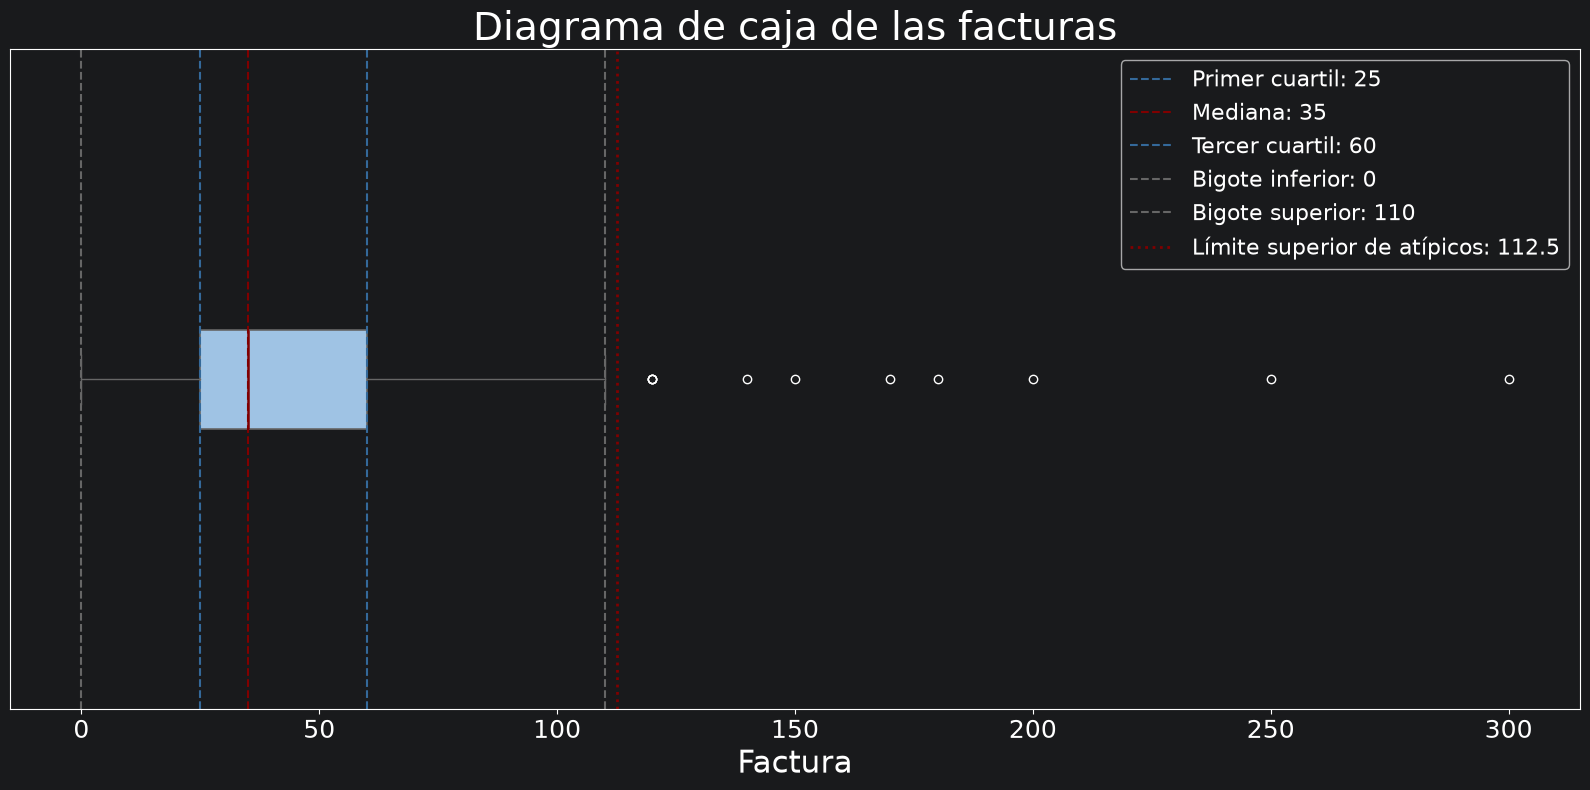

In [105]:
# Dibuja la caja de las facturas y añade referencias de cuartiles, bigotes y límite.
diagrama_caja(datos['Bill'], referencias=True,
              titulo='Diagrama de caja de las facturas', etiqueta='Factura')

**Versión simple — diagrama de caja.** Si solo necesitas ver mediana, cuartiles y atípicos, pandas dibuja la caja directamente. Sale vertical y sin las líneas de referencia del ejemplo anterior. Para el ejercicio, sustituye `Bill` por la variable numérica que quieras estudiar.

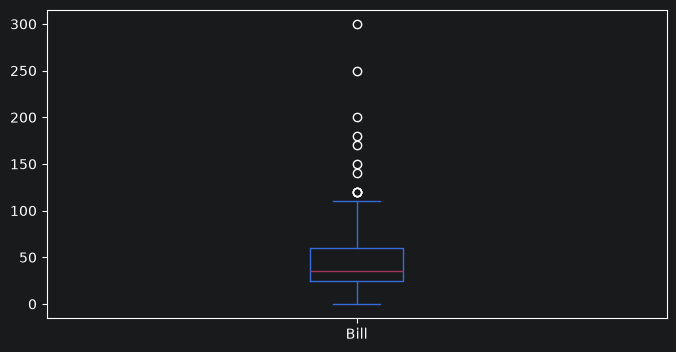

In [164]:
# Versión simple: caja de una variable numérica.
# Descarta facturas ausentes y crea una caja vertical; guarda el eje sin mostrarlo aparte.
_ = datos['Bill'].dropna().plot.box()
# Presenta el diagrama generado.
plt.show()

#### Histograma y densidad de la edad

Un histograma divide el eje de edades en **intervalos** y dibuja una barra por cada uno. En este caso `density=True` significa que el **área total**, no la suma de alturas, vale 1. Para un intervalo de anchura $h_j$ que contiene $n_j$ de las $n$ edades conocidas, la altura aproximada es:

$$
\widehat f_j=\frac{n_j}{n\,h_j},
\qquad
\sum_j \widehat f_j h_j=1.
$$

La franja roja resalta el tramo indicado en la llamada; su densidad media se aproxima dividiendo la **proporción observada en el tramo abierto** entre su amplitud. Cambia `intervalos` o `tramo` y vuelve a ejecutar la llamada para comparar gráficos. El número de barras puede alterar la apariencia sin cambiar los datos.

In [107]:
# Define una función para dibujar edades y medir su densidad en un tramo.
def histograma_edad(intervalos, tramo):
    # Conserva solo las edades observadas para el gráfico y los cálculos.
    edades = datos['Age'].dropna()
    # Extrae los dos extremos del tramo que se quiere destacar.
    inferior, superior = tramo
    # Prepara la figura y los ejes donde se dibujará el histograma.
    fig, ax = plt.subplots(figsize=(16, 8))
    # Agrupa edades en el número de intervalos indicado, con área total igual a uno.
    ax.hist(edades, bins=intervalos, density=True, color='#9fc3e4',
            edgecolor='#666666', linewidth=1.2)
    # Sombrea en rojo la franja comprendida entre los extremos elegidos.
    ax.axvspan(inferior, superior, color='#800000', alpha=0.15)
    # Coloca un título descriptivo encima de la figura.
    ax.set_title('Distribución de la edad', fontsize=20)
    # Indica que el eje horizontal representa edades.
    ax.set_xlabel('Edad', fontsize=16)
    # Indica que el eje vertical muestra densidades, no recuentos.
    ax.set_ylabel('Densidad', fontsize=16)
    # Ajusta el tamaño de los números de los ejes.
    ax.tick_params(labelsize=14)
    # Organiza los márgenes para evitar que se recorten los textos.
    fig.tight_layout()
    # Muestra el histograma terminado.
    plt.show()
    # Calcula la densidad del tramo solo si su anchura es positiva.
    if superior > inferior:
        # Halla la fracción de edades estrictamente dentro del tramo.
        proporcion = ((edades > inferior) & (edades < superior)).mean()
        # Muestra la proporción obtenida con cuatro decimales.
        print(f'Proporción en el intervalo abierto: {proporcion:.4f}')
        # Divide esa proporción entre la anchura del tramo y muestra la densidad media.
        print(f'Densidad media en el intervalo: {proporcion / (superior - inferior):.4f}')
    # Cuando el tramo no tiene anchura positiva, no se puede calcular esa densidad.
    else:
        # Pide separar los extremos para poder realizar el cálculo.
        print('Separa los extremos del tramo para calcular la densidad.')

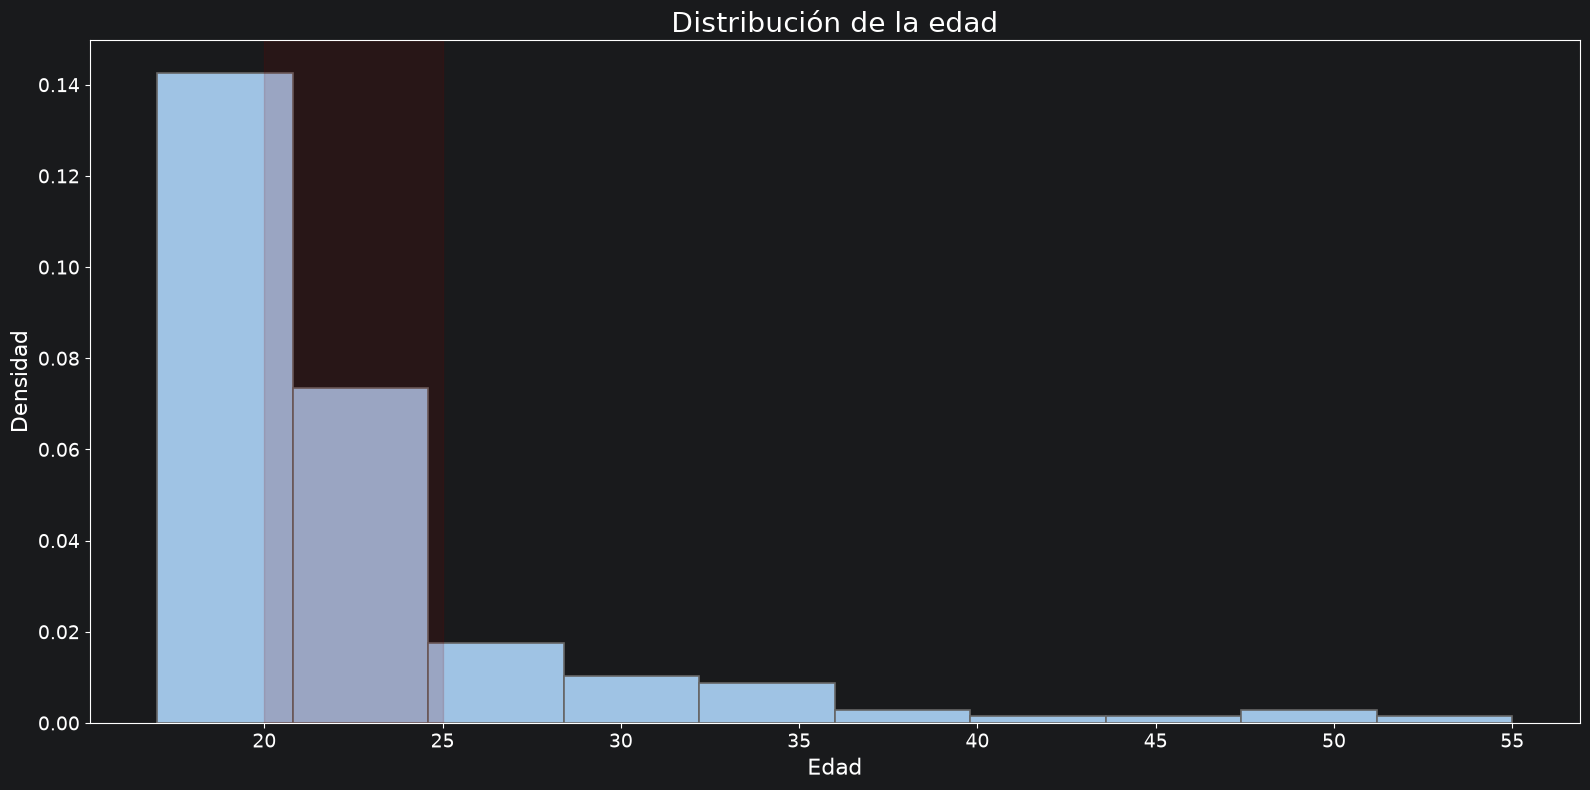

Proporción en el intervalo abierto: 0.2793
Densidad media en el intervalo: 0.0559


In [108]:
# Dibuja diez intervalos de edades y destaca el tramo entre 20 y 25 años.
histograma_edad(intervalos=10, tramo=(20, 25))

**Versión simple — histograma.** La llamada directa a pandas muestra la distribución de una variable numérica sin la franja sombreada ni los cálculos auxiliares del ejemplo anterior. `density=True` hace que el área total sea 1; cambia la columna y `bins` para reproducirlo en el ejercicio.

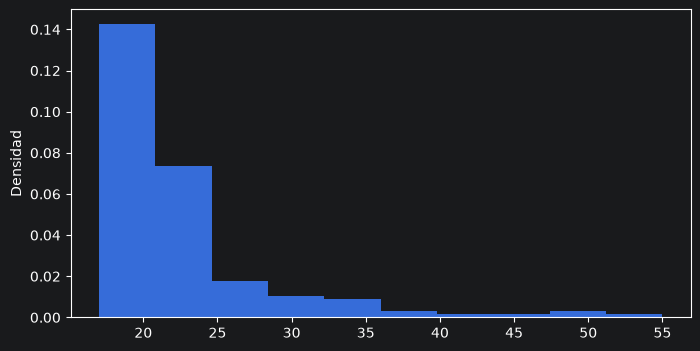

In [165]:
# Versión simple: histograma de densidad de una variable numérica.
# Dibuja las edades conocidas en diez barras cuya área total es uno.
_ = datos['Age'].dropna().plot.hist(bins=10, density=True)
# Nombra el eje vertical según la magnitud representada.
_ = plt.ylabel('Densidad')
# Muestra el histograma en el cuaderno.
plt.show()

**Versión simple — histograma de frecuencias.** Con las **mismas edades y los mismos 10 intervalos** del ejemplo anterior, `density=False` (valor predeterminado) hace que la altura de cada barra sea el **número de estudiantes** en ese intervalo. Con `density=True` la altura pasa a ser una densidad: $n_j/(n\,h_j)$, donde $h_j$ es la anchura de la barra; su **área** representa la proporción de casos. Compara los dos ejes verticales: las alturas no significan lo mismo.

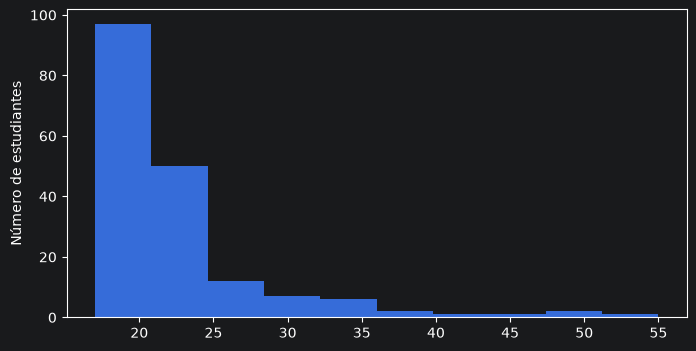

In [110]:
# Versión simple: las barras muestran recuentos, no densidades.
# Agrupa las edades conocidas en diez barras cuya altura es el número de casos.
_ = datos['Age'].dropna().plot.hist(bins=10, density=False)
# Indica que el eje vertical cuenta estudiantes.
_ = plt.ylabel('Número de estudiantes')
# Muestra el gráfico de frecuencias en el cuaderno.
plt.show()

**Microejercicio — histograma.** Dibuja en una sola línea de código un histograma de **frecuencias** de `Age` con 5 intervalos.

In [111]:
# Pista: En la versión simple, el número de intervalos y la escala vertical se configuran de forma independiente.
# Tu línea de código:

#### Densidad media entre 20 y 25 años

En el intervalo **abierto** $[20,25)$ contamos solo edades conocidas estrictamente mayores que 20 y menores que 25. Si $n_{(20,25)}$ es ese recuento y $n_{\text{edad}}$ el número de edades conocidas, entonces:

$$
\widehat p_{[20,25)}=\frac{n_{[20,25)}}{n_{\text{edad}}},
\qquad
\overline f_{[20,25)}=\frac{\widehat p_{[20,25)}}{25-20}.
$$

La primera cantidad es una **proporción**; la segunda, una **densidad media por año**. No confundas esta media sobre toda la franja con la altura de una barra concreta del histograma, cuyos bordes pueden ser diferentes.

In [112]:
# Extrae las edades conocidas para que las ausencias no alteren el denominador.
edades_validas = datos['Age'].dropna()
# Calcula la proporción de edades desde 20 incluido hasta 25 excluido y la divide entre cinco años.
((edades_validas >= 20) & (edades_validas < 25)).mean() / 5

np.float64(0.07374301675977654)

### Variable categórica: marca del móvil

Una marca es una **categoría**, no una magnitud a la que podamos calcular una media. Para cada marca $j$ distinguimos la frecuencia $f_j$ (**número de personas**), la proporción $p_j$ y el porcentaje:

$$
p_j=\frac{f_j}{n_{\text{marca válida}}},
\qquad
\text{porcentaje}_j=100p_j.
$$

`value_counts()` omite las marcas ausentes de forma predeterminada; por eso el denominador es el número de marcas **conocidas**, no todas las filas. En tres celdas separadas veremos **recuentos**, **proporciones** y **porcentajes**. Usamos el orden alfabético de las categorías para facilitar la comparación: verifica que las proporciones sumen 1, salvo redondeos posteriores.

In [166]:
# Cuenta cuántas veces aparece cada marca y ordena las marcas alfabéticamente.
frecuencias = datos["Brand"].value_counts(sort=False).sort_index()
# Muestra los recuentos obtenidos.
frecuencias

Brand
Alcatel        1
Ericsson       9
LG             3
Motorola      16
NEC            6
Nokia        104
Panasonic      6
Phillips       1
Samsung        8
Sharp          1
Siemens       10
Sony           7
mno            1
samsung        1
Name: count, dtype: int64

#### De frecuencias a proporciones

La celda anterior cuenta personas por marca. `normalize=True` realiza ahora la división por el total de **marcas conocidas**, de modo que cada valor pasa de un recuento entero a una fracción entre 0 y 1. Compara ambas series: el orden de las marcas debe ser el mismo.

In [167]:
# Calcula la fracción de marcas conocidas correspondiente a cada marca y ordénalas por nombre.
proporciones = datos["Brand"].value_counts(normalize=True, sort=False).sort_index()
# Muestra las proporciones calculadas.
proporciones

Brand
Alcatel      0.005747
Ericsson     0.051724
LG           0.017241
Motorola     0.091954
NEC          0.034483
Nokia        0.597701
Panasonic    0.034483
Phillips     0.005747
Samsung      0.045977
Sharp        0.005747
Siemens      0.057471
Sony         0.040230
mno          0.005747
samsung      0.005747
Name: proportion, dtype: float64

#### Mostrar porcentajes

Multiplicamos las proporciones por 100 y redondeamos a una cifra decimal para comunicar resultados fácilmente. El redondeo puede hacer que la suma de los porcentajes mostrados no sea exactamente 100 %; no cambia las proporciones originales guardadas en `proporciones`.

In [168]:
# Convierte las proporciones en porcentajes y redondea el resultado a un decimal.
(100 * proporciones).round(1)

Brand
Alcatel       0.6
Ericsson      5.2
LG            1.7
Motorola      9.2
NEC           3.4
Nokia        59.8
Panasonic     3.4
Phillips      0.6
Samsung       4.6
Sharp         0.6
Siemens       5.7
Sony          4.0
mno           0.6
samsung       0.6
Name: proportion, dtype: float64

#### Diagrama de barras por marca

Cada barra representa una **marca diferente**: su altura es la frecuencia $f_j$ en estudiantes y el eje horizontal identifica la categoría. Este gráfico utiliza el azul claro y los bordes grises de la sesión 2; las etiquetas y el título permiten interpretar la figura sin consultar la celda de código.

No es un histograma: aquí no hay intervalos de una escala numérica y separar las barras es natural. Reordenar las categorías cambia la presentación, pero **no** los recuentos. Para mostrar porcentajes en lugar de personas habría que graficar `proporciones * 100` y cambiar la etiqueta del eje vertical.

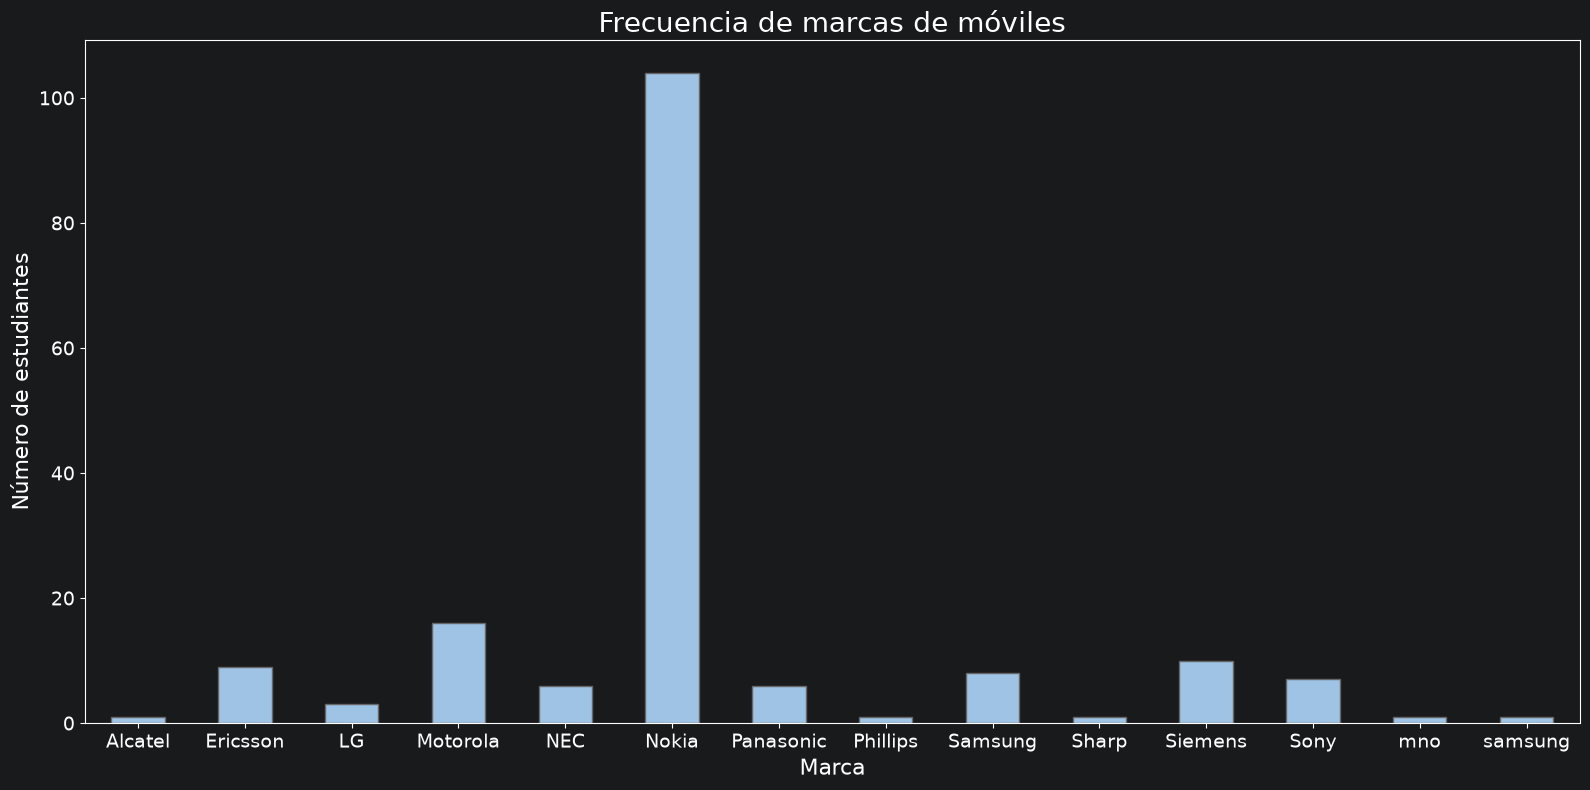

In [116]:
# Crea la figura y sus ejes con el tamaño indicado.
fig, ax = plt.subplots(figsize=(16, 8))
# Dibuja una barra por marca; el guion bajo descarta el objeto gráfico devuelto.
_ = frecuencias.plot.bar(ax=ax, color='#9fc3e4', edgecolor='#666666', rot=0)
# Añade el título del gráfico.
_ = ax.set_title('Frecuencia de marcas de móviles', fontsize=20)
# Nombra el eje horizontal con la variable representada.
_ = ax.set_xlabel('Marca', fontsize=16)
# Indica que la altura de las barras cuenta estudiantes.
_ = ax.set_ylabel('Número de estudiantes', fontsize=16)
# Ajusta el tamaño del texto en los ejes.
ax.tick_params(labelsize=14)
# Deja espacio para que las etiquetas no se recorten.
fig.tight_layout()
# Muestra la figura terminada.
plt.show()

#### Barras ordenadas por frecuencia

Podemos comparar el **orden alfabético** con el **orden por frecuencia** sin cambiar `datos`. El primero facilita encontrar una marca concreta; el segundo ayuda a identificar cuáles son más y menos comunes. Giramos las etiquetas 90° para que no se solapen cuando aparecen muchas marcas.

La primera celda define cómo se reconstruye la tabla; la segunda dibuja las barras por frecuencia. Cambia `ordenar=True` a `ordenar=False` y ejecuta de nuevo la llamada para ver el orden alfabético. En ambos casos las barras muestran **recuentos**, no proporciones.

In [117]:
# Define una función que puede ordenar las barras por frecuencia o por marca.
def barras_marcas(ordenar):
    # Cuenta las marcas conocidas y parte del orden alfabético.
    tabla_marcas = datos['Brand'].value_counts(sort=False).sort_index()
    # Solo si se solicita, cambia el orden al de los recuentos.
    if ordenar:
        # Coloca primero las marcas con menos estudiantes.
        tabla_marcas = tabla_marcas.sort_values()
    # Prepara una figura y unos ejes para el gráfico.
    fig, ax = plt.subplots(figsize=(16, 8))
    # Dibuja las barras y gira los nombres para que no se solapen.
    _ = tabla_marcas.plot.bar(ax=ax, rot=90, color='#9fc3e4', edgecolor='#666666')
    # Pone el título sobre las barras.
    _ = ax.set_title('Marcas de móviles', fontsize=20)
    # Identifica las marcas en el eje horizontal.
    _ = ax.set_xlabel('Marca', fontsize=16)
    # Identifica los recuentos en el eje vertical.
    _ = ax.set_ylabel('Número de estudiantes', fontsize=16)
    # Agranda las etiquetas de ambos ejes.
    ax.tick_params(labelsize=14)
    # Evita que las etiquetas queden cortadas.
    fig.tight_layout()
    # Presenta el gráfico.
    plt.show()

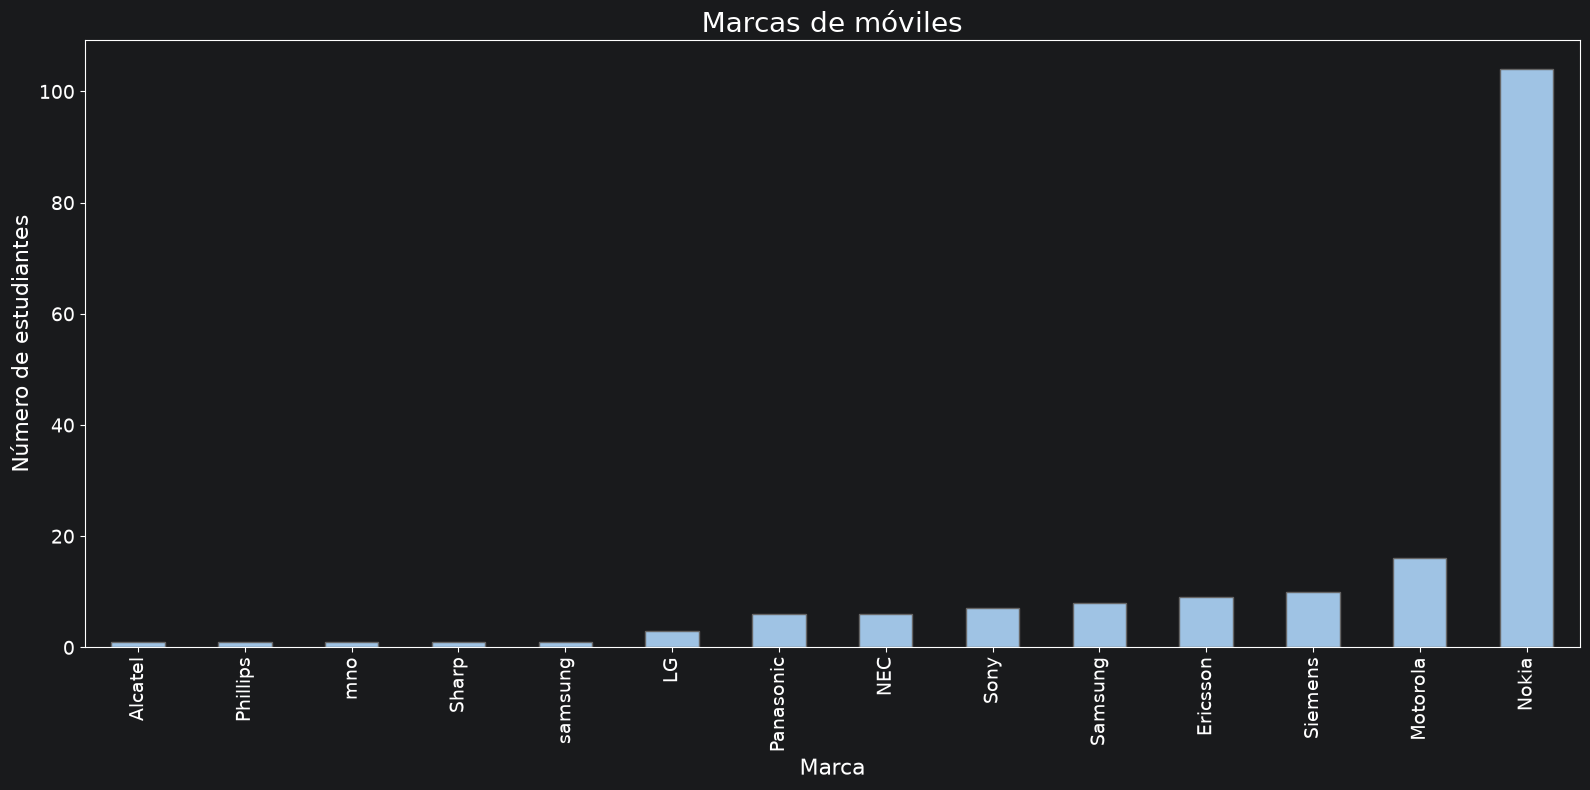

In [118]:
# Ejecuta la función con las marcas ordenadas por número de estudiantes.
barras_marcas(ordenar=True)
# Cambia a ordenar=False para ver el orden alfabético.

**Versión simple — barras para categorías.** `value_counts()` calcula cuántos casos conocidos hay en cada categoría y `plot.bar()` los dibuja. Sustituye `Brand` por otra variable categórica, como `origin` en el ejercicio.

**Microejercicio — marcas.** Dibuja en una sola línea de código un gráfico de barras con las **proporciones** de cada `Brand` conocida.

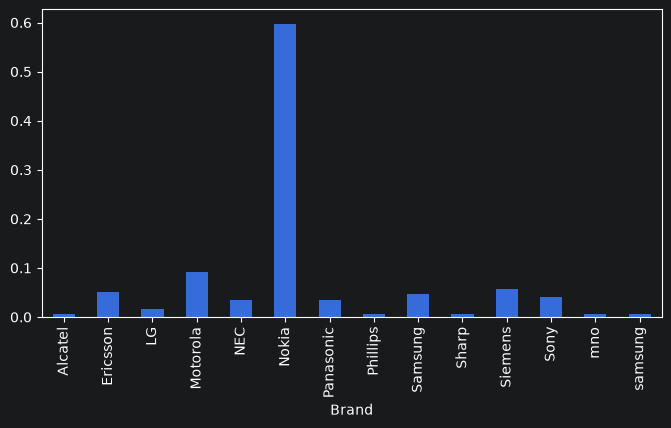

In [189]:
# Versión simple: barras de recuentos de una variable categórica.
# Cuenta las marcas conocidas y dibuja una barra con su recuento para cada una.
proporciones = datos["Brand"].value_counts(normalize=True, sort=False).sort_index().plot.bar()

### Ejercicio 1.5 — Describir dos tipos de variables

Utiliza el fichero de vuelos que cargaste como `datos2` en el ejercicio 1.3. Trata cada columna según su **naturaleza**:

1. `air_time` mide minutos en el aire: indica el número de casos válidos, centro, dispersión, cuartiles y un gráfico **numérico**. ¿Hay vuelos muy largos que puedan desplazar la media?
R/ se podria decir que si ya que La mayoría de los vuelos son cortos el 50% equivale a 129 min, pero la cola de vuelos largos eleva la media a  150,7 min más de 20 minutos por encima de la mediana.

2. `origin` identifica un aeropuerto de salida: calcula **frecuencias y proporciones** entre orígenes conocidos y represéntalas con **barras**. ¿Por qué no sería adecuado un histograma numérico?

Escribe los análisis en sus respectivas celdas de pistas. Antes de comparar resultados, comprueba qué filas carecen de la variable de interés; no uses automáticamente el total de vuelos como denominador.

In [201]:
datos2 = pd.read_csv(DATA_PATH/"flights.txt", sep="\t", na_values=["@"])
datos2

,year,month,day,dep_time,dep_delay,arr_time,arr_delay,carrier,tailnum,flight,origin,dest,air_time,distance,hour,minute
0,2013,1,1,517.0,2.0,830.0,11.0,UA,N14228,1545,EWR,IAH,227.0,1400,5.0,17.0
1,2013,1,1,533.0,4.0,850.0,20.0,UA,N24211,1714,LGA,IAH,227.0,1416,5.0,33.0
2,2013,1,1,542.0,2.0,923.0,33.0,AA,N619AA,1141,JFK,MIA,160.0,1089,5.0,42.0
3,2013,1,1,544.0,-1.0,1004.0,-18.0,B6,N804JB,725,JFK,BQN,183.0,1576,5.0,44.0
4,2013,1,1,554.0,-6.0,812.0,-25.0,DL,N668DN,461,LGA,ATL,116.0,762,5.0,54.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
336771,2013,9,30,NaN,NaN,NaN,NaN,9E,NaN,3393,JFK,DCA,NaN,213,NaN,NaN
336772,2013,9,30,NaN,NaN,NaN,NaN,9E,NaN,3525,LGA,SYR,NaN,198,NaN,NaN
336773,2013,9,30,NaN,NaN,NaN,NaN,MQ,N535MQ,3461,LGA,BNA,NaN,764,NaN,NaN
336774,2013,9,30,NaN,NaN,NaN,NaN,MQ,N511MQ,3572,LGA,CLE,NaN,419,NaN,NaN


In [202]:
# 1.5.1 — Descriptiva numérica del tiempo en el aire.
# Recupera datos2 del ejercicio 1.3 y selecciona air_time excluyendo ausentes.
datos2 = pd.read_csv(DATA_PATH/"flights.txt", sep="\t", na_values=["@"])
air_time = datos2["air_time"].dropna()
print(air_time)


0         227.0
1         227.0
2         160.0
3         183.0
4         116.0
          ...  
336765     41.0
336766     52.0
336767     47.0
336768     33.0
336769    196.0
Name: air_time, Length: 327346, dtype: float64


In [203]:
# Examina tamaño, tendencia central, dispersión y cuartiles como en la descriptiva de Bill.
print(air_time.describe())

count    327346.000000
mean        150.686460
std          93.688305
min          20.000000
25%          82.000000
50%         129.000000
75%         192.000000
max         695.000000
Name: air_time, dtype: float64


In [210]:
recuentos = datos2["origin"].value_counts()
proporciones = datos2["origin"].value_counts(normalize=True)
recuentos
proporciones

origin
EWR    120835
JFK    111279
LGA    104662
Name: count, dtype: int64

origin
EWR    0.358799
JFK    0.330424
LGA    0.310776
Name: proportion, dtype: float64

<Axes: xlabel='air_time', ylabel='Density'>

Text(0.5, 1.0, 'Distribución y curva de densidad de air_time')

Text(0.5, 0, 'Minutos en el aire')

Text(0, 0.5, 'Densidad')

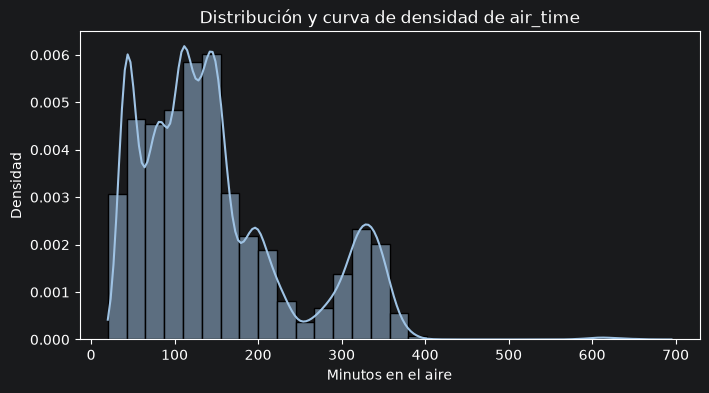

In [208]:
# Elige un gráfico adecuado para una variable numérica: ¿se aprecian colas o atípicos?
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(air_time, bins=30, kde=True, stat="density", edgecolor="black", color="#9fc3e4")
plt.title("Distribución y curva de densidad de air_time")
plt.xlabel("Minutos en el aire")
plt.ylabel("Densidad")
plt.show()

<Axes: xlabel='origin'>

Text(0.5, 1.0, 'Proporción de vuelos por aeropuerto de origen')

Text(0.5, 0, 'Aeropuerto')

Text(0, 0.5, 'Proporción')

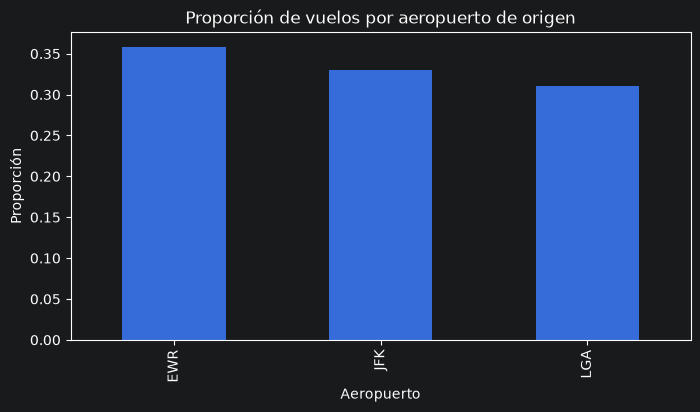

In [211]:
proporciones.plot.bar()
plt.title("Proporción de vuelos por aeropuerto de origen")
plt.xlabel("Aeropuerto")
plt.ylabel("Proporción")
plt.show()

In [191]:
# 1.5.2 — Descriptiva categórica del aeropuerto de origen.
# Trabaja ahora con origin: cuenta vuelos por aeropuerto y calcula sus proporciones.
# Dibuja un gráfico de barras; ¿por qué no usarías un histograma para categorías?
# Contrasta el denominador de las proporciones con el número de orígenes conocidos.
# Conservamos solo los vuelos cuyo aeropuerto de origen se conoce.

## Descriptiva bivariante

Ahora relacionaremos **dos variables de la misma persona**. Hay tres situaciones distintas: dos magnitudes numéricas (`Age` y `Bill`), dos categorías (`PlanType` y `PrimaryUse`) o una magnitud (`Bill`) comparada entre grupos (`PlanType`). Cada análisis responde a una pregunta diferente; no tiene sentido resumirlos todos con un único estadístico.

Para evitar comparaciones entre personas distintas, utilizamos **pares completos**: una fila solo contribuye cuando conocemos ambas variables pertinentes. El número de pares puede cambiar de un análisis a otro según dónde falten datos.

### Dos variables numéricas: edad y factura

#### Correlación de Pearson

La correlación cuantifica la **asociación lineal** de los pares $(x_i,y_i)$ de edad y factura. Sobre los $n$ pares completos se calcula:

$$
r=\frac{\sum_{i=1}^{n}(x_i-\bar x)(y_i-\bar y)}{\sqrt{\sum_{i=1}^{n}(x_i-\bar x)^2}\,\sqrt{\sum_{i=1}^{n}(y_i-\bar y)^2}}.
$$

Su valor está entre $-1$ y $1$: el signo indica dirección y el valor absoluto, intensidad de la **relación lineal**. Un valor cercano a cero no descarta asociaciones no lineales; los atípicos pueden alterar $r$ y **correlación no implica causalidad**. Primero calculamos la correlación directamente y después extraemos el mismo resultado de la matriz de correlaciones.

In [123]:
# Calcula la correlación lineal de edad y factura usando los pares disponibles.
datos["Age"].corr(datos["Bill"])

np.float64(0.2900709854542838)

**La misma correlación desde una matriz.** `corr()` construye los coeficientes para las dos columnas y `.loc['Age', 'Bill']` selecciona la entrada cruzada. Compara este número con el resultado anterior: la diagonal de la matriz, en cambio, compara cada variable consigo misma.

In [212]:
# Construye la matriz de correlaciones y selecciona el cruce entre edad y factura.
datos[["Age", "Bill"]].corr().loc["Age", "Bill"]  # Mediante la matriz de correlaciones

np.float64(0.2900709854542837)

#### Pearson y Spearman: ¿qué relación miden?

**Pearson** resume la asociación **lineal** entre los valores. **Spearman** aplica la correlación a sus **rangos** (posiciones ordenadas), por lo que también puede captar una asociación **monótona** que sea curva: cuando una variable crece, la otra tiende siempre a crecer o siempre a decrecer. Ninguno de los dos coeficientes resume bien una relación en forma de U. Compáralos sobre **los mismos pares completos** de edad y factura; si difieren, inspecciona la nube de puntos antes de atribuirles una forma o una causa.

In [125]:
# Ambos coeficientes se calculan con las mismas personas.
# Conserva solo personas con edad y factura conocidas.
pares_correlacion = datos[['Age', 'Bill']].dropna()
# Calcula Pearson para la asociación lineal y muestra tres decimales.
print(f"Pearson:  {pares_correlacion['Age'].corr(pares_correlacion['Bill']):.3f}")
# Calcula Spearman sobre rangos de esos mismos pares y muestra tres decimales.
print(f"Spearman: {pares_correlacion['Age'].corr(pares_correlacion['Bill'], method='spearman'):.3f}")

Pearson:  0.290
Spearman: 0.076


**Microejercicio — Spearman.** Calcula en una sola línea de código la correlación de Spearman entre `Bill` y `No.Phones`, usando solo pares completos.

In [126]:
# Pista: Selecciona las dos columnas y cambia el método de correlación; evita mezclar filas incompletas.
# Tu línea de código:

#### Correlación espuria: un factor común

En estos **12 días simulados**, la temperatura influye por separado en las ventas de helados y protectores solares. Cada punto representa un día y su color indica la temperatura. Aunque las ventas resulten correlacionadas, vender helados **no provoca** en esta simulación que se vendan más protectores: ambas cantidades comparten un factor. Una correlación, por alta que sea, no demuestra causalidad. **Son datos inventados** para ilustrar la idea, no observaciones de los móviles.

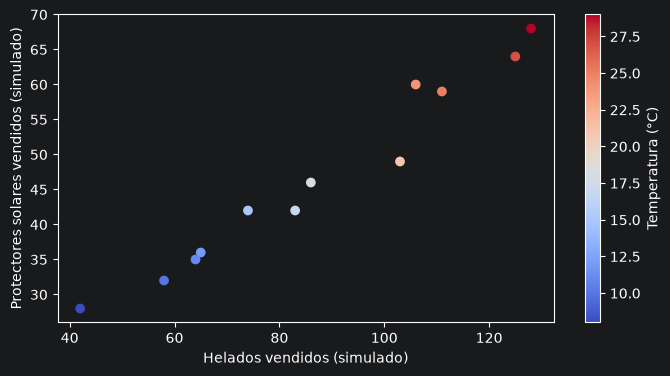

Correlación simulada: 0.98


In [127]:
# Ejemplo ficticio: dos ventas dependen de la temperatura, no una de la otra.
# Define las temperaturas observadas en doce días ficticios.
temperaturas = np.array([8, 10, 12, 15, 18, 21, 24, 27, 29, 25, 17, 11])
# Fija la semilla del generador para obtener siempre la misma simulación.
rng = np.random.default_rng(42)
# Simula ventas de helados que aumentan con la temperatura más un pequeño ruido.
helados = 15 + 4 * temperaturas + rng.integers(-5, 6, size=len(temperaturas))
# Simula por separado ventas de protectores también ligadas a la temperatura.
protectores = 10 + 2 * temperaturas + rng.integers(-3, 4, size=len(temperaturas))
# Extrae la correlación entre ambas series simuladas de la matriz calculada.
r_simulado = np.corrcoef(helados, protectores)[0, 1]
# Dibuja un punto por día y colorea cada punto según su temperatura.
puntos = plt.scatter(helados, protectores, c=temperaturas, cmap='coolwarm')
# Etiqueta el eje horizontal con las ventas de helados.
_ = plt.xlabel('Helados vendidos (simulado)')
# Etiqueta el eje vertical con las ventas de protectores.
_ = plt.ylabel('Protectores solares vendidos (simulado)')
# Añade una escala para interpretar el color de cada punto.
_ = plt.colorbar(puntos, label='Temperatura (°C)')
# Muestra el gráfico de los días simulados.
plt.show()
# Presenta la correlación simulada redondeada a dos decimales.
print(f'Correlación simulada: {r_simulado:.2f}')

#### Diagramas de dispersión

En una nube de puntos cada observación válida tiene coordenadas $(\text{edad},\text{factura})$. La figura revela superposiciones, valores extremos y posibles relaciones curvilíneas que un solo coeficiente de correlación puede ocultar. **No trazamos una línea causal**: el gráfico solo muestra cómo coinciden las dos medidas dentro de la muestra.

Primero dibujamos los pares con Matplotlib y el estilo azul claro/borde negro de la sesión 2. Después añadimos **líneas rojas para las medianas** de los mismos pares completos: los cuatro cuadrantes ayudan a comparar observaciones por encima y por debajo de cada centro. Por último, construiremos la nube básica desde pandas para comparar las dos API. Las tres celdas son gráficos separados, cada uno con sus ejes y propósito.

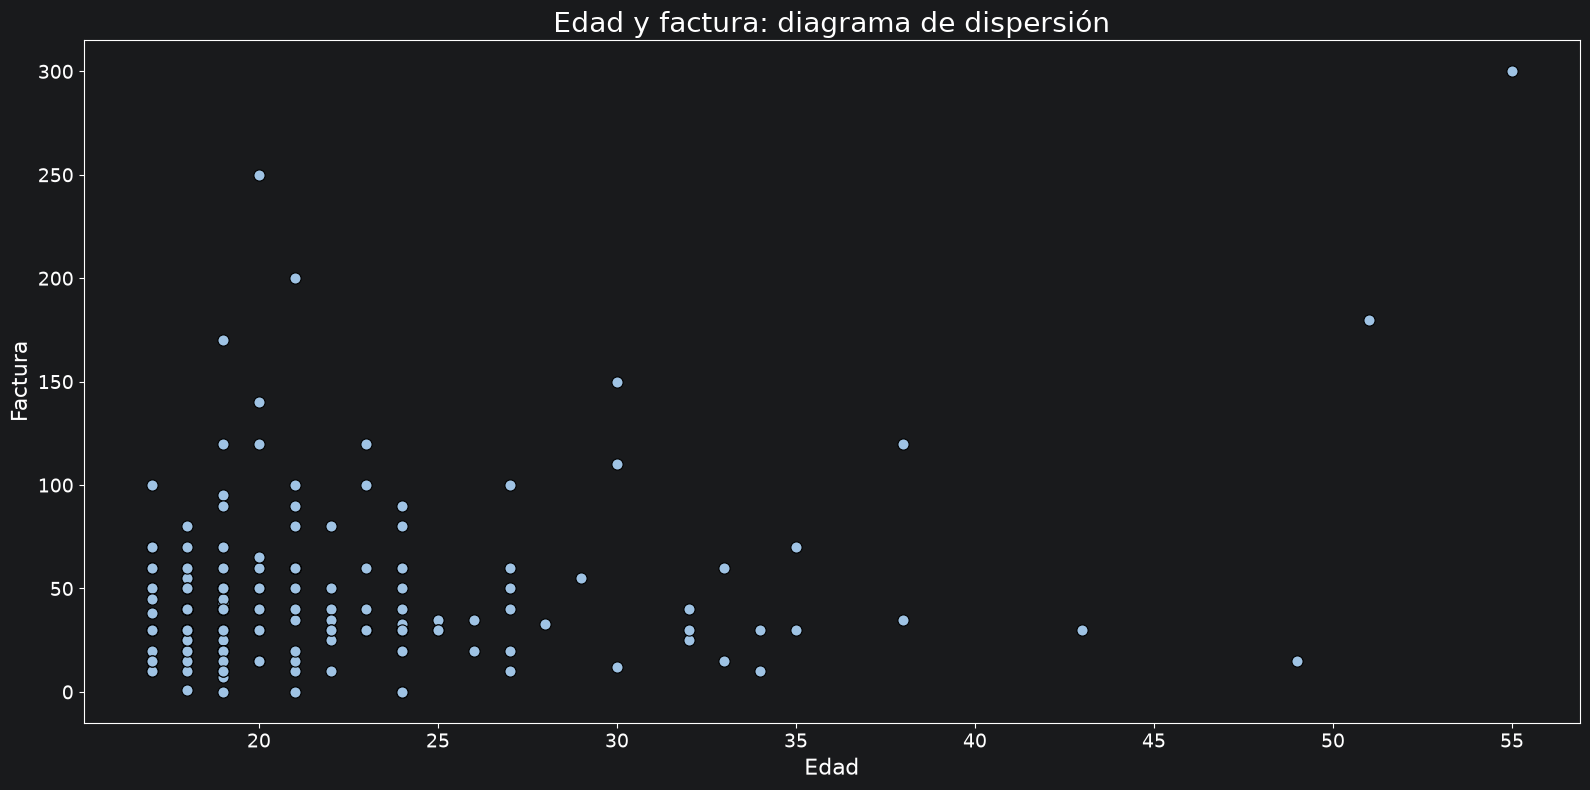

In [128]:
# Selecciona solo filas con edad y factura conocidas.
pares = datos[['Age', 'Bill']].dropna()
# Prepara una figura y sus ejes para la nube de puntos.
fig, ax = plt.subplots(figsize=(16, 8))
# Dibuja cada par completo con edad en horizontal y factura en vertical.
_ = ax.scatter(pares['Age'], pares['Bill'], s=65, color='#9fc3e4',
               edgecolor='black', linewidth=0.8)
# Explica qué variables compara el gráfico en el título.
_ = ax.set_title('Edad y factura: diagrama de dispersión', fontsize=20)
# Nombra el eje de las edades.
_ = ax.set_xlabel('Edad', fontsize=16)
# Nombra el eje de las facturas.
_ = ax.set_ylabel('Factura', fontsize=16)
# Amplía el texto de las marcas de ambos ejes.
ax.tick_params(labelsize=14)
# Ajusta los márgenes para evitar cortes.
fig.tight_layout()
# Muestra la nube de puntos.
plt.show()

**Añadir referencias de centro.** Reutilizamos los pares completos para que las medianas vertical y horizontal describan precisamente los puntos dibujados. Las líneas rojas separan valores mayores y menores que cada mediana; no son rectas de regresión ni indican por sí solas una asociación.

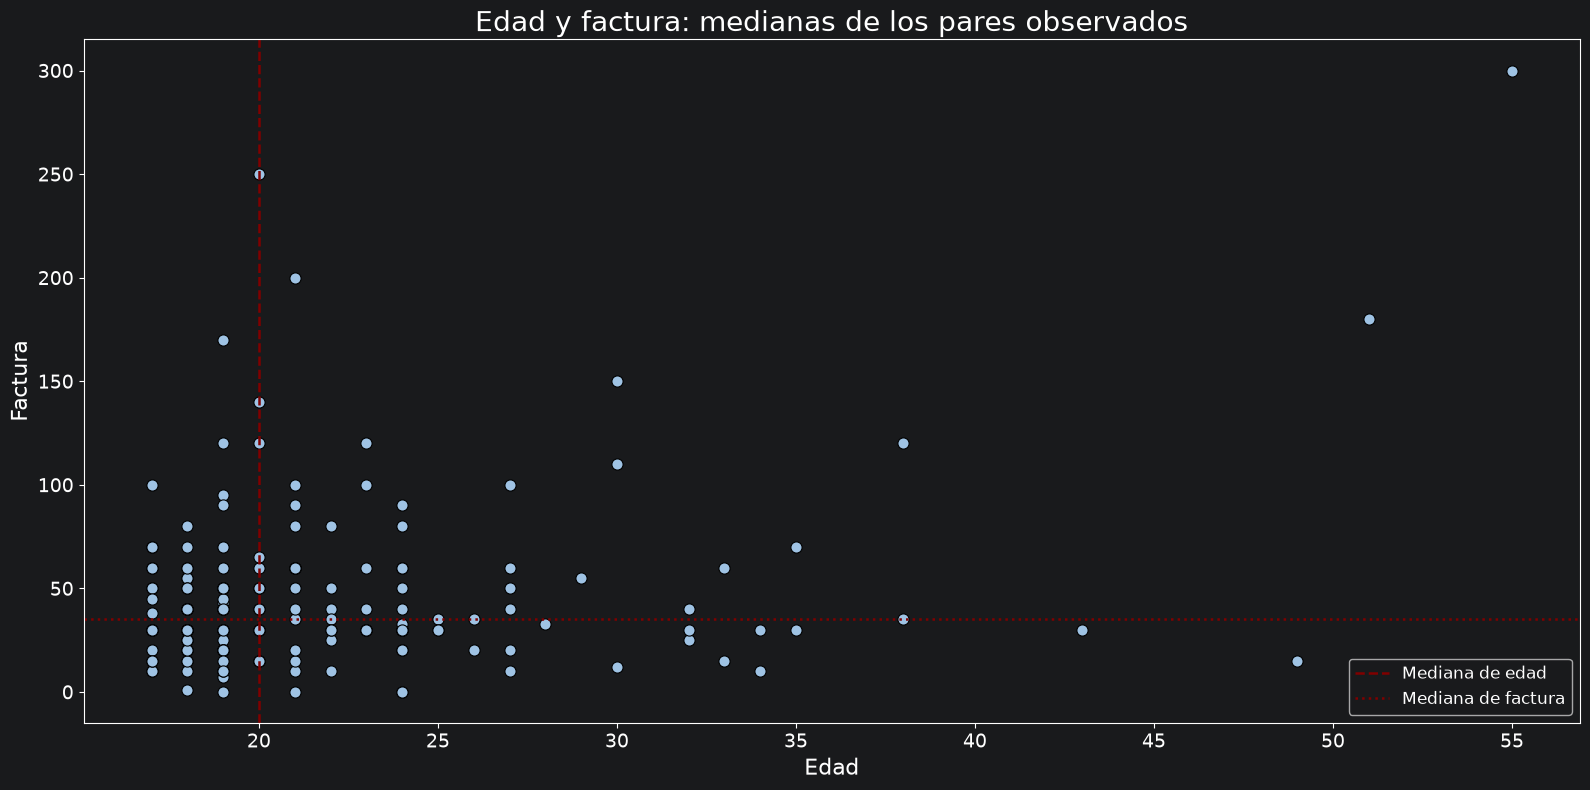

In [129]:
# Crea una nueva figura y sus ejes.
fig, ax = plt.subplots(figsize=(16, 8))
# Sitúa un punto por persona con ambas medidas conocidas.
_ = ax.scatter(pares['Age'], pares['Bill'], s=65, color='#9fc3e4',
               edgecolor='black', linewidth=0.8)
# Marca con una línea vertical la mediana de edad de los pares representados.
_ = ax.axvline(pares['Age'].median(), color='#800000', linestyle='--',
               linewidth=1.8, label='Mediana de edad')
# Marca con una línea horizontal la mediana de factura de los mismos pares.
_ = ax.axhline(pares['Bill'].median(), color='#800000', linestyle=':',
               linewidth=1.8, label='Mediana de factura')
# Titula el gráfico para indicar que aparecen las medianas.
_ = ax.set_title('Edad y factura: medianas de los pares observados', fontsize=20)
# Nombra el eje horizontal de edad.
_ = ax.set_xlabel('Edad', fontsize=16)
# Nombra el eje vertical de factura.
_ = ax.set_ylabel('Factura', fontsize=16)
# Ajusta el tamaño de los números de los ejes.
ax.tick_params(labelsize=14)
# Muestra una leyenda para identificar ambas medianas.
_ = ax.legend(fontsize=12)
# Ajusta los márgenes de la figura.
fig.tight_layout()
# Muestra el gráfico con sus líneas de referencia.
plt.show()

**La misma nube con pandas.** `datos.plot.scatter(...)` crea el gráfico a partir de los nombres de las columnas y devuelve los ejes para ajustar título, escalas y tipografía. Es otra forma de construir la **nube sin líneas de referencia**; compara el resultado con la primera figura, no con los cuadrantes de la segunda.

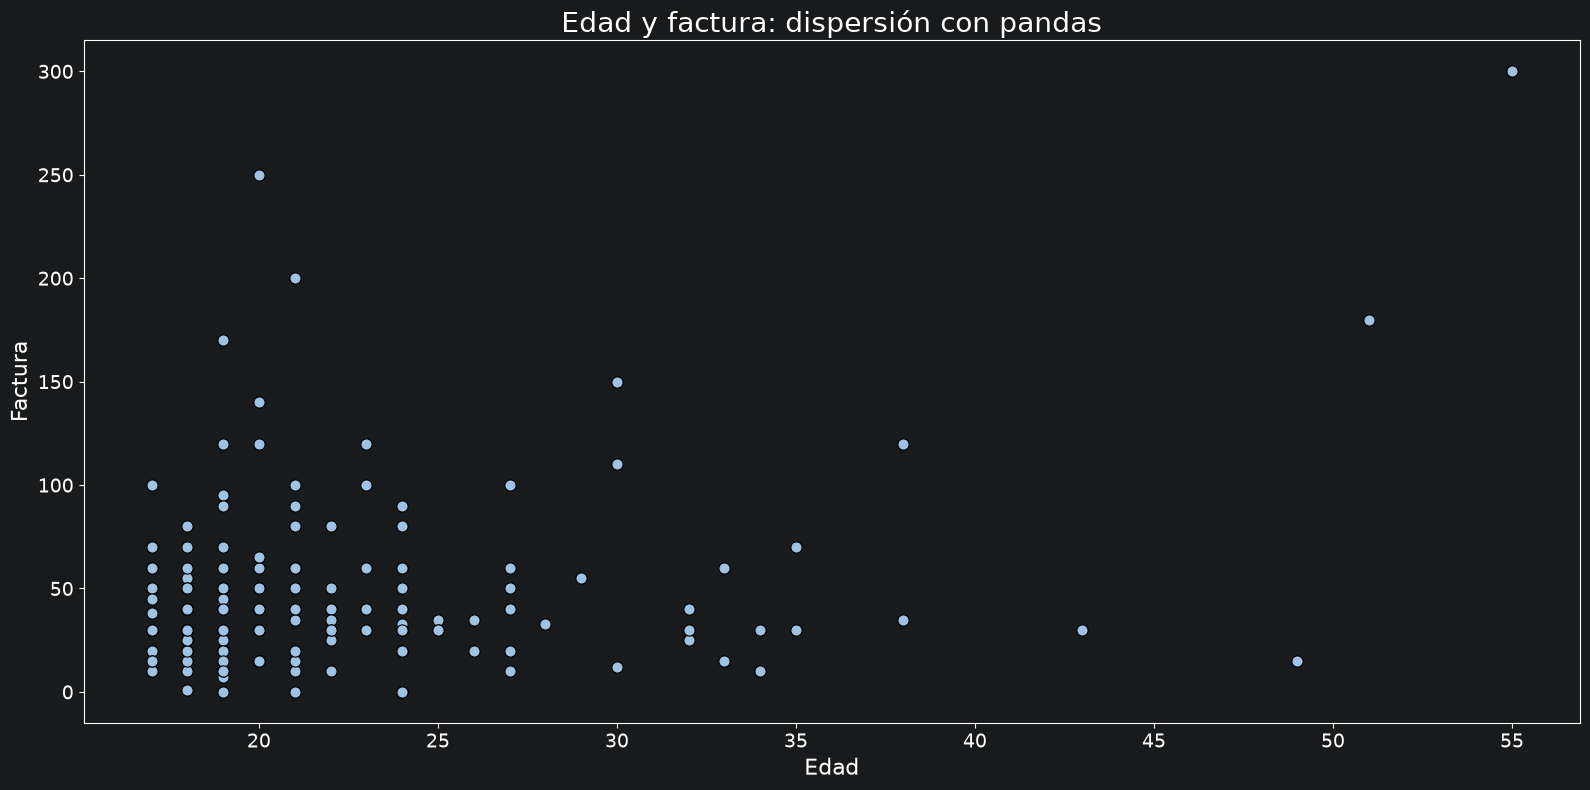

In [130]:
# Dibuja la nube de los pares completos con pandas y guarda sus ejes.
ax = pares.plot.scatter(x='Age', y='Bill', figsize=(16, 8),
                        color='#9fc3e4', edgecolor='black',
                        linewidth=0.8, s=65)
# Da un título descriptivo a la nube.
_ = ax.set_title('Edad y factura: dispersión con pandas', fontsize=20)
# Identifica la edad en el eje horizontal.
_ = ax.set_xlabel('Edad', fontsize=16)
# Identifica la factura en el eje vertical.
_ = ax.set_ylabel('Factura', fontsize=16)
# Agranda las marcas de los ejes.
ax.tick_params(labelsize=14)
# Ajusta los márgenes de la figura creada por pandas.
ax.figure.tight_layout()
# Muestra el gráfico terminado.
plt.show()

**Versión simple — dispersión.** Con dos columnas numéricas, `plot.scatter()` dibuja los pares conocidos sin configurar colores, títulos ni medianas. Para los vuelos del ejercicio, cambia las columnas de edad y factura por los dos retrasos.

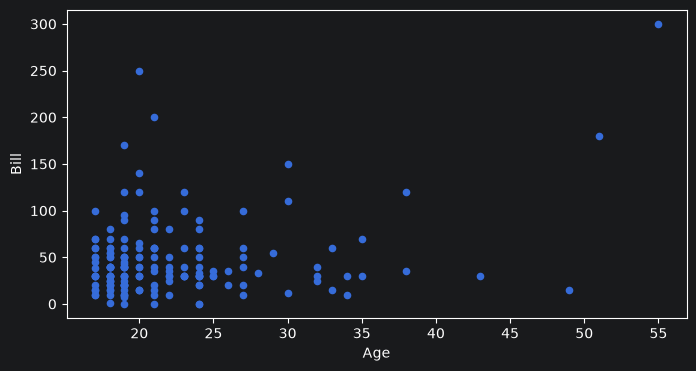

In [131]:
# Versión simple: dos variables numéricas de las mismas filas.
# Elimina los pares incompletos y dibuja edad frente a factura.
_ = datos[['Age', 'Bill']].dropna().plot.scatter(x='Age', y='Bill')
# Muestra la nube resultante.
plt.show()

**Microejercicio — nube de puntos.** Dibuja en una sola línea de código `Bill` en el eje horizontal y `Age` en el vertical, usando solo parejas conocidas.

In [132]:
# Pista: Reutiliza la versión simple invirtiendo qué variable asignas a cada eje.
# Tu línea de código:

**Versión simple — hexágonos (`hexbin`).** Si muchos puntos coinciden, este gráfico muestra la concentración por zonas. Conserva solo las filas con ambas medidas conocidas y usa `plt.hexbin()`, igual que pide el ejercicio de vuelos: sustituye las dos columnas de edad y factura por los dos retrasos.

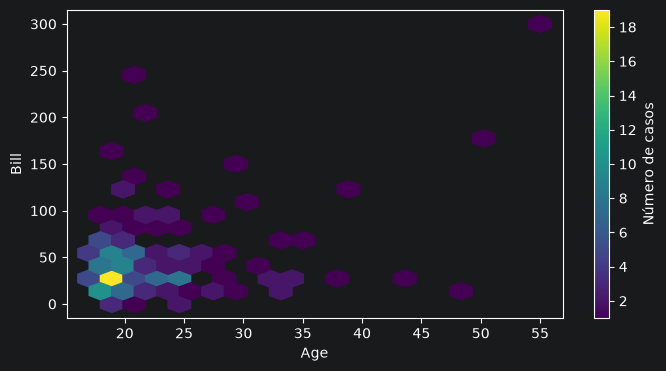

In [133]:
# Versión simple: concentración de pares en hexágonos.
# Descarta las filas donde falte la edad o la factura.
pares = datos[['Age', 'Bill']].dropna()
# Cuenta los pares de cada hexágono y oculta los hexágonos vacíos.
_ = plt.hexbin(pares['Age'], pares['Bill'], gridsize=20, mincnt=1)
# Etiqueta el eje horizontal de edad.
_ = plt.xlabel('Age')
# Etiqueta el eje vertical de factura.
_ = plt.ylabel('Bill')
# Añade una barra que traduce los colores en números de casos.
_ = plt.colorbar(label='Número de casos')
# Muestra el mapa de concentraciones.
plt.show()

#### Logaritmos y separación de puntos superpuestos

En la nube original se superponen personas con la misma edad y factura. El **jitter** añade pequeños desplazamientos visuales $\varepsilon_x$ y $\varepsilon_y$ para que se distingan los puntos; se generan con una semilla fija, pero **no cambian los datos de `datos`**. El argumento `dispersion` fija el desplazamiento máximo $d$ de cada eje: $\varepsilon_x,\varepsilon_y\in[-d,d]$.

Si `logaritmos=True`, se aplican logaritmos **antes** de desplazar los puntos:

$$
x_i'=\log(\mathrm{Age}_i)+\varepsilon_{x,i},
\qquad
y_i'=\log(\mathrm{Bill}_i+0{,}1)+\varepsilon_{y,i}.
$$

El $0{,}1$ permite transformar facturas de valor cero; con `logaritmos=False` los ejes recuperan las unidades originales. Una escala transformada puede hacer más visibles diferencias entre facturas pequeñas, pero **ya no se lee directamente en euros**. Cambia los argumentos de la llamada y vuelve a ejecutarla; usa `dispersion=0` para comparar posiciones exactas y no confundas el ruido gráfico con variabilidad real.

In [134]:
# Define una función para comparar escalas y separar puntos superpuestos.
def dispersion_edad_factura(logaritmos, dispersion):
    # Conserva solo las observaciones con ambas variables conocidas.
    pares = datos[['Age', 'Bill']].dropna()
    # Convierte las edades en números para transformarlas y desplazarlas.
    x = pares['Age'].to_numpy(dtype=float)
    # Convierte las facturas en números para transformarlas y desplazarlas.
    y = pares['Bill'].to_numpy(dtype=float)
    # Aplica logaritmos únicamente si se piden ejes transformados.
    if logaritmos:
        # Transforma la edad mediante su logaritmo.
        x = np.log(x)
        # Suma 0,1 para admitir facturas cero antes de tomar el logaritmo.
        y = np.log(y + 0.1)
    # Fija una semilla para repetir los mismos desplazamientos gráficos.
    rng = np.random.default_rng(42)
    # Desplaza ligeramente las posiciones horizontales sin cambiar los datos originales.
    x = x + rng.uniform(-dispersion, dispersion, size=len(x))
    # Desplaza ligeramente las posiciones verticales sin cambiar los datos originales.
    y = y + rng.uniform(-dispersion, dispersion, size=len(y))
    # Prepara la figura y sus ejes.
    fig, ax = plt.subplots(figsize=(16, 8))
    # Dibuja un punto por pareja en las posiciones visuales calculadas.
    ax.scatter(x, y, color='#9fc3e4', edgecolor='black', linewidth=0.8, s=65)
    # Titula la comparación de edad y factura.
    ax.set_title('Relación entre edad y factura', fontsize=20)
    # Indica si el eje horizontal usa edades originales o logaritmos.
    ax.set_xlabel('log(Edad)' if logaritmos else 'Edad', fontsize=16)
    # Indica si el eje vertical usa facturas originales o logaritmos.
    ax.set_ylabel('log(Factura + 0,1)' if logaritmos else 'Factura', fontsize=16)
    # Agranda las etiquetas numéricas de los ejes.
    ax.tick_params(labelsize=14)
    # Ajusta el espacio para las etiquetas y el título.
    fig.tight_layout()
    # Muestra el gráfico configurado.
    plt.show()

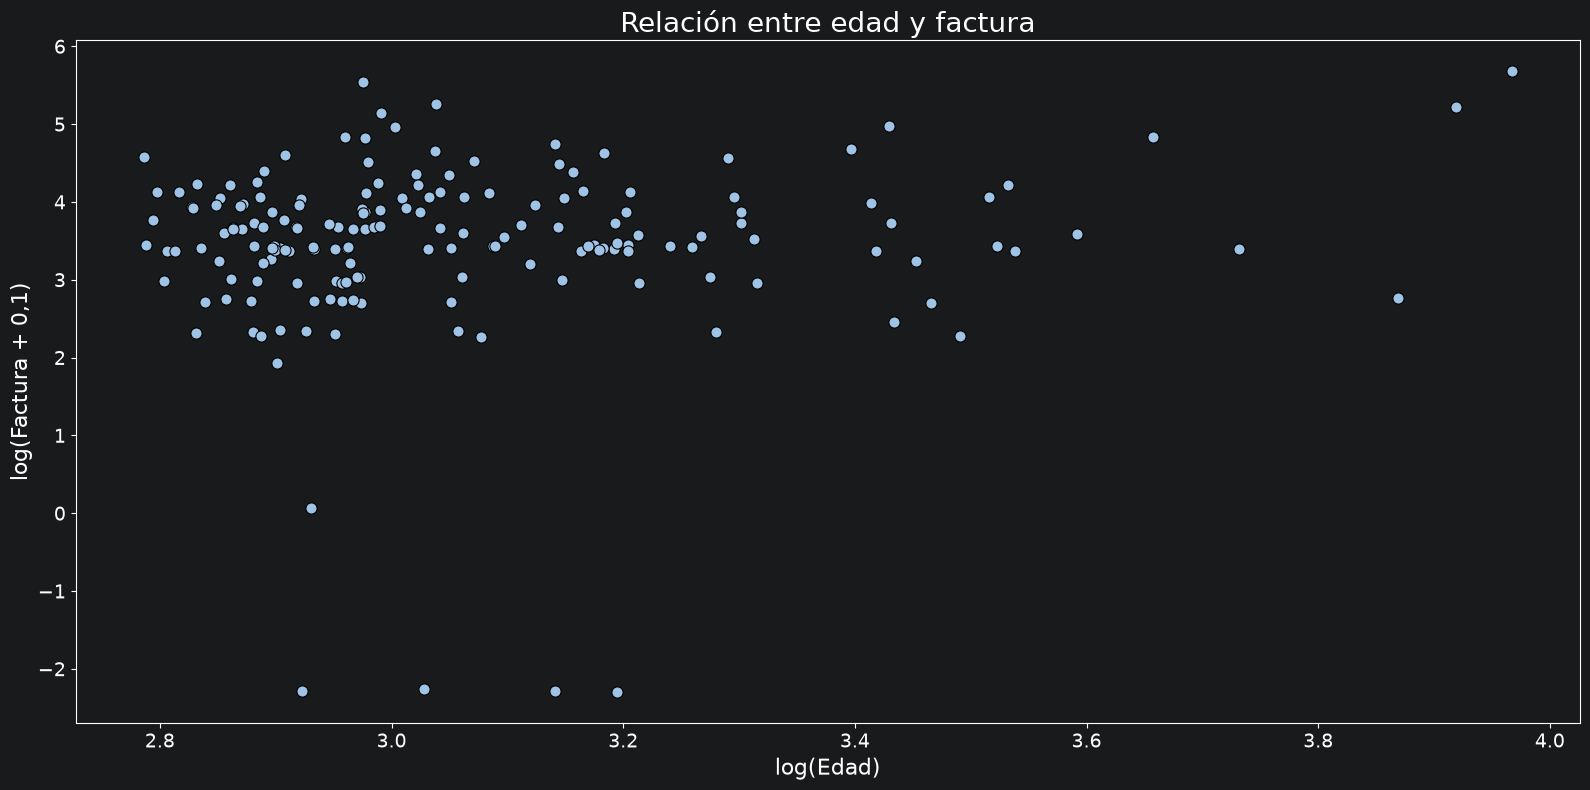

In [135]:
# Dibuja los logaritmos con pequeños desplazamientos para separar puntos coincidentes.
dispersion_edad_factura(logaritmos=True, dispersion=0.05)
# Para ver las unidades originales sin desplazamiento: dispersion_edad_factura(False, 0).

### Dos variables categóricas: contrato y uso

#### Tabla de frecuencias cruzadas

La tabla coloca `PlanType` en las **filas** ($i$) y `PrimaryUse` en las **columnas** ($j$). Una celda $n_{ij}$ cuenta las personas con **ambas** categorías: por ejemplo, un tipo de contrato y un uso principal concretos. Si falta cualquiera de las dos variables, esa persona no puede asignarse a una celda.

$$
n=\sum_i\sum_j n_{ij},
$$

donde $n$ es el número de **pares categóricos completos**, no necesariamente el total de filas de `datos`. Primero mostramos recuentos; después cambiaremos el denominador para formular preguntas diferentes sobre las mismas frecuencias.

In [136]:
# Cuenta las personas para cada combinación conocida de contrato y uso principal.
pd.crosstab(datos["PlanType"], datos["PrimaryUse"])  # Frecuencias

PrimaryUse,Both,Calls,SMS
PlanType,,,
Plan,33,22,21
Prepaid,35,16,47


#### Proporciones globales: una combinación en toda la muestra válida

Con `normalize='all'`, cada frecuencia se divide por **todos los pares completos** de la tabla:

$$
p_{ij}^{\mathrm{global}}=\frac{n_{ij}}{n},
\qquad \sum_i\sum_j p_{ij}^{\mathrm{global}}=1.
$$

La celda expresa qué fracción del conjunto válido reúne **ese contrato y ese uso a la vez**. No responde qué porcentaje dentro de un contrato prefiere cierto uso: para ello necesitamos la normalización por filas.

In [137]:
# Divide cada recuento de contrato y uso por el total de pares conocidos.
pd.crosstab(datos["PlanType"], datos["PrimaryUse"], normalize="all")  # Proporciones globales

PrimaryUse,Both,Calls,SMS
PlanType,,,
Plan,0.189655,0.126437,0.120690
Prepaid,0.201149,0.091954,0.270115


#### Proporciones por fila: usos dentro de cada contrato

`normalize='index'` divide cada celda por el **total de su fila** $n_{i+}=\sum_j n_{ij}$:

$$
p_{j\mid i}=\frac{n_{ij}}{n_{i+}},
\qquad \sum_j p_{j\mid i}=1.
$$

Ahora la pregunta es: **entre quienes tienen un contrato dado, qué parte usa principalmente el móvil de cada manera?** Compara las filas de `Plan` y `Prepaid`: su total se ha igualado a 1, aunque los tamaños originales de los grupos puedan diferir. Estas proporciones son condicionales al contrato.

In [138]:
# Divide cada casilla por el total de su contrato (su fila).
pd.crosstab(datos["PlanType"], datos["PrimaryUse"], normalize="index")  # Proporciones por filas

PrimaryUse,Both,Calls,SMS
PlanType,,,
Plan,0.434211,0.289474,0.276316
Prepaid,0.357143,0.163265,0.479592


#### Proporciones por columna: contratos dentro de cada uso

`normalize='columns'` divide por el **total de la columna** $n_{+j}=\sum_i n_{ij}$:

$$
p_{i\mid j}=\frac{n_{ij}}{n_{+j}},
\qquad \sum_i p_{i\mid j}=1.
$$

Esta vez preguntamos: **entre quienes usan el móvil principalmente de una forma, qué parte tiene cada contrato?** No intercambies $p_{i\mid j}$ y $p_{j\mid i}$: condicionan a grupos distintos y pueden ser diferentes aun cuando procedan de la misma casilla de la tabla original.

In [139]:
# Divide cada casilla por el total de su uso principal (su columna).
pd.crosstab(datos["PlanType"], datos["PrimaryUse"], normalize="columns")  # Proporciones por columnas

PrimaryUse,Both,Calls,SMS
PlanType,,,
Plan,0.485294,0.578947,0.308824
Prepaid,0.514706,0.421053,0.691176


#### Comparar las cuatro tablas

La celda siguiente presenta **frecuencias**, proporciones **globales**, **por contrato** (filas) y **por uso** (columnas), sin alterar las observaciones. Antes de interpretar una casilla, formula la pregunta completa: «¿qué porcentaje de **qué grupo** representa esta combinación?». La función `tabla_contrato_uso(normalizacion)` permite repetir cada consulta por separado.

Comprueba las sumas: **todas** las celdas al normalizar globalmente, cada **fila** al normalizar por contrato y cada **columna** al normalizar por uso deben sumar 1 salvo redondeo.

In [140]:
# Define una función para mostrar la tabla con la normalización elegida.
def tabla_contrato_uso(normalizacion):
    # Construye las frecuencias o proporciones solicitadas y muestra la tabla.
    display(pd.crosstab(datos["PlanType"], datos["PrimaryUse"], normalize=normalizacion))

In [141]:
# Recorre los cuatro nombres y modos de normalizar las tablas.
for nombre, normalizacion in (
    ('Frecuencias', False), ('Proporciones globales', 'all'),
    ('Proporciones por contrato', 'index'), ('Proporciones por uso', 'columns'),
):
    # Escribe el nombre de la tabla que se va a consultar.
    print(nombre)
    # Muestra la tabla con el denominador correspondiente.
    tabla_contrato_uso(normalizacion)

Frecuencias


PrimaryUse,Both,Calls,SMS
PlanType,,,
Plan,33,22,21
Prepaid,35,16,47


Proporciones globales


PrimaryUse,Both,Calls,SMS
PlanType,,,
Plan,0.189655,0.126437,0.120690
Prepaid,0.201149,0.091954,0.270115


Proporciones por contrato


PrimaryUse,Both,Calls,SMS
PlanType,,,
Plan,0.434211,0.289474,0.276316
Prepaid,0.357143,0.163265,0.479592


Proporciones por uso


PrimaryUse,Both,Calls,SMS
PlanType,,,
Plan,0.485294,0.578947,0.308824
Prepaid,0.514706,0.421053,0.691176


#### Barras apiladas: comparar totales y composición

Cada barra representa **un tipo de contrato**; su altura total es el número de personas con ambas categorías conocidas en ese grupo. Los segmentos azul claro, azul medio y azul oscuro separan los **usos principales**. La suma de las alturas de sus segmentos reproduce el total de la fila correspondiente de la tabla cruzada.

El gráfico permite comparar tamaños de grupo y composición **en recuentos**. No confundas el área de un segmento con un porcentaje: si un contrato incluye más personas, un segmento más alto no demuestra por sí solo que el uso sea proporcionalmente más frecuente en él. Para esta última pregunta consulta las proporciones por fila.

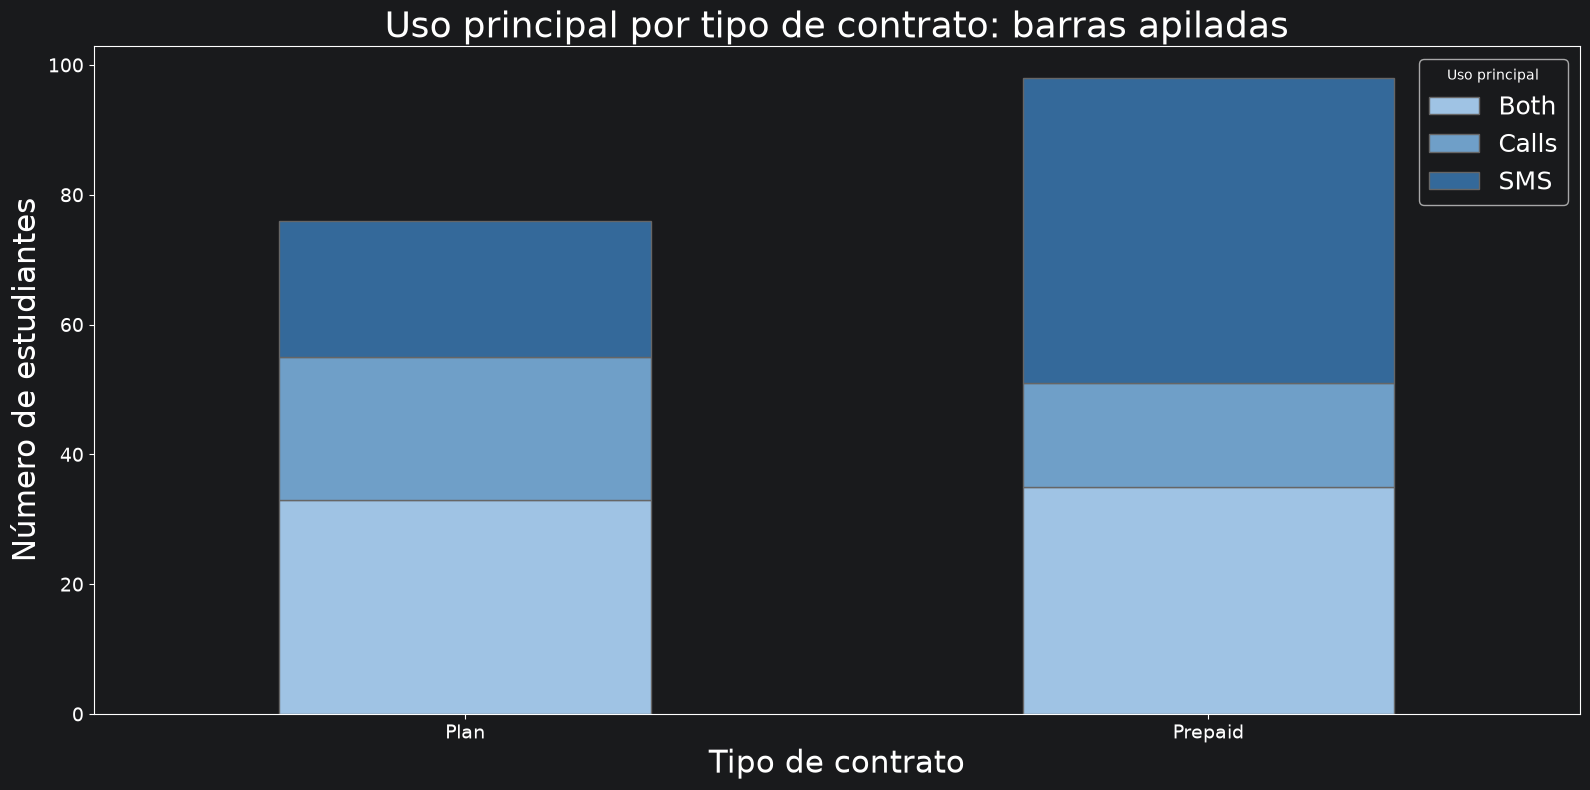

In [142]:
# Cuenta personas por uso y contrato, dejando fuera pares incompletos.
tabla_uso_plan = pd.crosstab(datos['PrimaryUse'], datos['PlanType'])
# Crea la figura y los ejes del gráfico.
fig, ax = plt.subplots(figsize=(16, 8))
# Transpone la tabla para que cada contrato sea una barra con usos apilados.
_ = tabla_uso_plan.T.plot.bar(stacked=True, ax=ax, color=['#9fc3e4', '#6f9fc8', '#34699a'],
                              edgecolor='#666666', rot=0)
# Describe el contenido de las barras en el título.
_ = ax.set_title('Uso principal por tipo de contrato: barras apiladas', fontsize=26)
# Identifica los contratos en el eje horizontal.
_ = ax.set_xlabel('Tipo de contrato', fontsize=22)
# Indica que el eje vertical cuenta estudiantes.
_ = ax.set_ylabel('Número de estudiantes', fontsize=22)
# Amplía el texto de los ejes.
ax.tick_params(labelsize=14)
# Identifica los colores de los diferentes usos.
_ = ax.legend(title='Uso principal', fontsize=18)
# Ajusta los márgenes para que todo se lea bien.
fig.tight_layout()
# Muestra las barras apiladas.
plt.show()

#### Barras agrupadas: comparar cada uso entre contratos

Volvemos a graficar **las mismas frecuencias** sin apilar: en cada contrato aparece una barra por uso principal. Así podemos comparar mejor la **altura de un mismo color** entre contratos, porque todas las barras parten de cero. En cambio, el total del contrato deja de leerse como una única altura.

El código reutiliza la tabla creada en la celda de barras apiladas; ejecútala antes si acabas de reiniciar el kernel. Igual que antes, las alturas son **personas**, no porcentajes, por lo que debes mirar el tamaño de cada grupo antes de concluir que una preferencia es más frecuente proporcionalmente.

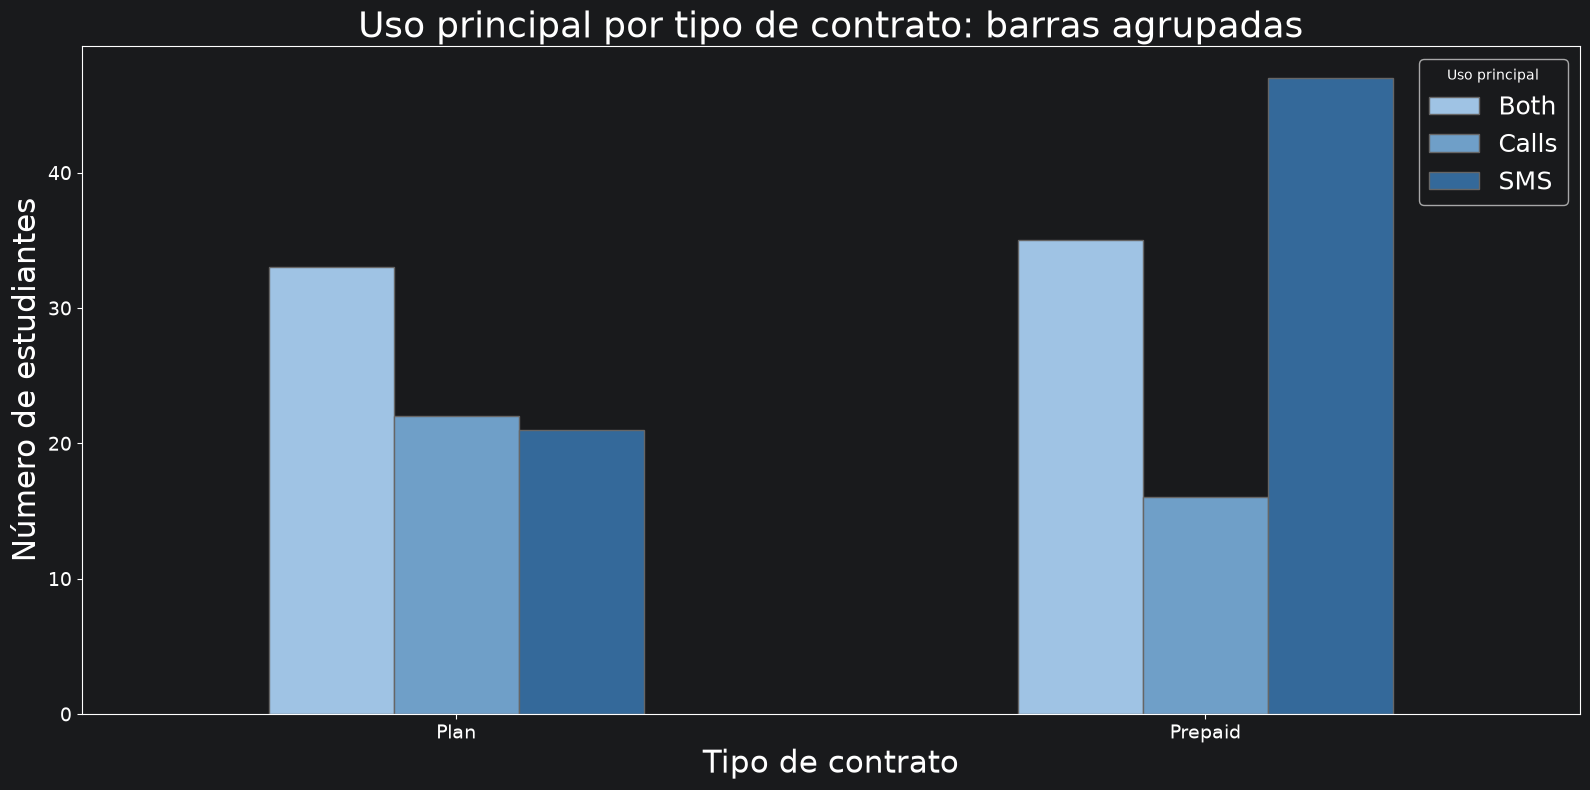

In [143]:
# Prepara una figura diferente para comparar barras sin apilar.
fig, ax = plt.subplots(figsize=(16, 8))
# Transpone la tabla y coloca una barra por uso al lado de las otras de su contrato.
_ = tabla_uso_plan.T.plot.bar(stacked=False, ax=ax, color=['#9fc3e4', '#6f9fc8', '#34699a'],
                              edgecolor='#666666', rot=0)
# Aclara en el título que las barras están agrupadas.
_ = ax.set_title('Uso principal por tipo de contrato: barras agrupadas', fontsize=26)
# Nombra el eje de los tipos de contrato.
_ = ax.set_xlabel('Tipo de contrato', fontsize=22)
# Nombra el eje de los recuentos de estudiantes.
_ = ax.set_ylabel('Número de estudiantes', fontsize=22)
# Ajusta el tamaño de las etiquetas de los ejes.
ax.tick_params(labelsize=14)
# Añade una leyenda para reconocer cada uso.
_ = ax.legend(title='Uso principal', fontsize=18)
# Evita que se recorten las etiquetas.
fig.tight_layout()
# Muestra las barras agrupadas.
plt.show()

**Versión simple — barras de dos categorías.** Con una tabla cruzada ya puedes dibujar barras **apiladas** o **agrupadas** cambiando solo `stacked`. `pd.crosstab` omite los pares con categorías ausentes; usa los nombres de tus dos columnas para repetirlo.

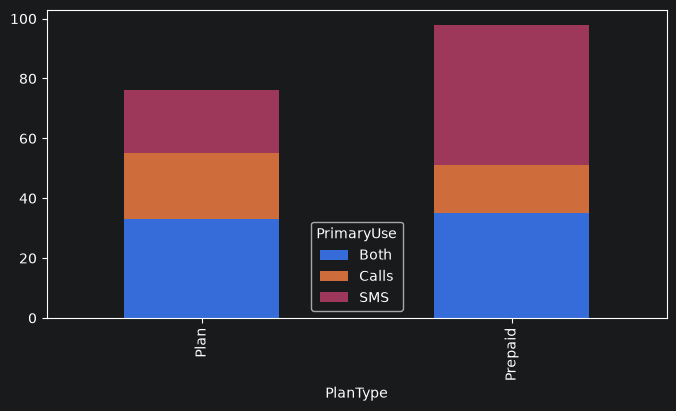

In [144]:
# Versión simple: recuentos por contrato y uso.
# Construye la tabla de combinaciones de contrato y uso conocido.
cruce = pd.crosstab(datos['PlanType'], datos['PrimaryUse'])
# Dibuja una barra apilada para cada contrato.
_ = cruce.plot.bar(stacked=True)
# Muestra la comparación gráfica.
plt.show()
# Cambia stacked=True a False para barras agrupadas.

#### Mosaico: área conjunta y altura condicionada

Cada rectángulo identifica un **uso** $j$ y un **contrato** $i$. Su **área** representa la proporción conjunta $n_{ij}/n$; la **anchura** de la columna es la proporción de personas con ese uso $n_{+j}/n$ y su **altura dentro de la columna** es la fracción con ese contrato $n_{ij}/n_{+j}$:

$$
\frac{n_{ij}}{n}=\frac{n_{+j}}{n}\cdot\frac{n_{ij}}{n_{+j}}.
$$

Compara las alturas azules dentro de distintos usos para buscar diferencias de composición. El mosaico usa solo filas con **ambos datos conocidos**, como la tabla cruzada; una variación visible es descriptiva y por sí sola no prueba causalidad ni significación estadística.

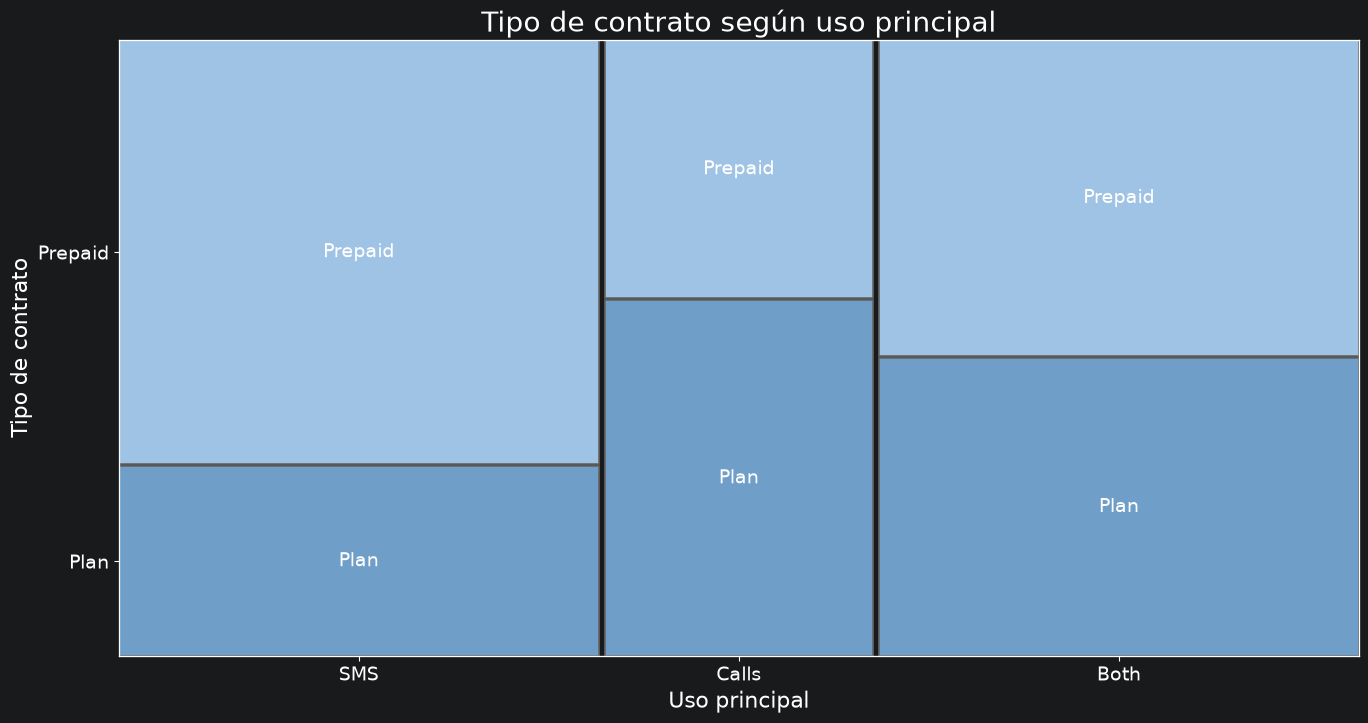

In [145]:
# Asigna un color a cada tipo de contrato.
colores_plan = {'Plan': '#6f9fc8', 'Prepaid': '#9fc3e4'}
# Prepara el espacio en el que se dibujará el mosaico.
fig, ax = plt.subplots(figsize=(16, 8))
# Usa solo pares conocidos y dibuja rectángulos por uso y contrato;
# las funciones breves eligen el color del contrato y su etiqueta.
_ = mosaic(datos.dropna(subset=['PrimaryUse', 'PlanType']), ['PrimaryUse', 'PlanType'], ax=ax,
           properties=lambda clave: {'facecolor': colores_plan[clave[1]],
                                     'edgecolor': '#666666', 'linewidth': 1.2},
           labelizer=lambda clave: clave[1])
# Indica en el título qué dos categorías relaciona el mosaico.
_ = ax.set_title('Tipo de contrato según uso principal', fontsize=20)
# Etiqueta el eje horizontal con el uso principal.
_ = ax.set_xlabel('Uso principal', fontsize=16)
# Etiqueta el eje vertical con el tipo de contrato.
_ = ax.set_ylabel('Tipo de contrato', fontsize=16)
# Agranda las marcas de ambos ejes.
ax.tick_params(labelsize=14)
# Recorre las etiquetas escritas dentro de los rectángulos.
for etiqueta in ax.texts:
    # Hace más legible el texto de cada rectángulo.
    etiqueta.set_fontsize(14)
# Muestra el mosaico acabado.
plt.show()

**Versión simple — mosaico.** Sin personalizar colores ni etiquetas, basta con elegir las dos categorías y conservar las filas donde se conocen ambas. La función `mosaic` ya está importada al principio del cuaderno.

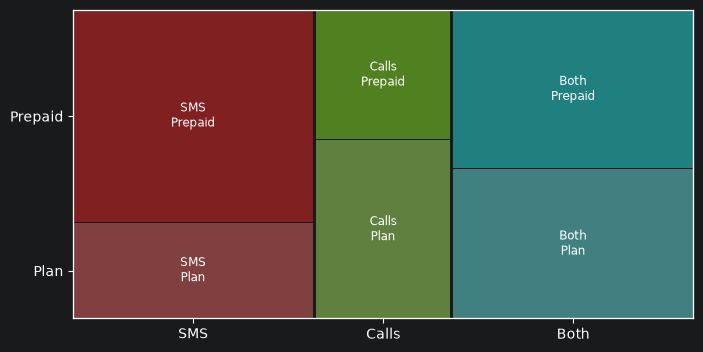

In [146]:
# Versión simple: mosaico de dos variables categóricas.
# Conserva pares conocidos y dibuja el mosaico de usos y contratos.
_ = mosaic(datos.dropna(subset=['PrimaryUse', 'PlanType']), ['PrimaryUse', 'PlanType'])
# Muestra el mosaico sin personalización adicional.
plt.show()

### Variable numérica frente a una categoría

#### Factura por tipo de contrato

Ahora `Bill` es la magnitud numérica y `PlanType` define los grupos `Plan` y `Prepaid`. El resumen global describe **todas las facturas conocidas**; los resúmenes por contrato describen solo personas con **factura y tipo de contrato conocidos**. Por ello la media global no debe interpretarse como «la media típica de cualquiera de los dos grupos».

Primero consulta `datos['Bill'].describe()`. Luego compara, dentro de cada contrato, $n_i$, media, mediana, cuartiles y dispersión. La **desviación típica muestral** del grupo se calcula con $n_i-1$ en el denominador: un grupo con mayor media no tiene necesariamente mayor variabilidad. Finalmente, las cajas mostrarán si hay asimetría y posibles valores extremos.

In [147]:
# Resume las facturas conocidas con recuento, centro, dispersión y cuartiles.
datos["Bill"].describe()

count    174.000000
mean      46.850575
std       41.577570
min        0.000000
25%       25.000000
50%       35.000000
75%       60.000000
max      300.000000
Name: Bill, dtype: float64

#### Resumen por grupo

`groupby('PlanType', observed=True)` separa las facturas conocidas según el tipo de contrato realmente observado; `describe()` calcula el resumen **dentro de cada grupo**. Contrasta las medianas y los cuartiles además de las medias: unos pocos importes altos pueden afectar desigualmente a los dos grupos.

In [148]:
# Agrupa las facturas por contrato y calcula su resumen dentro de cada grupo observado.
datos.groupby("PlanType", observed=True)["Bill"].describe()

,count,mean,std,min,25%,50%,75%,max
PlanType,,,,,,,,
Plan,76.0,61.171053,51.058499,0.0,32.25,40.0,70.0,300.0
Prepaid,98.0,35.744898,27.966958,0.0,20.00,30.0,50.0,200.0


#### Comparar solo la dispersión de cada contrato

La siguiente celda aísla la **desviación típica muestral** de `Bill` en cada grupo (`ddof=1`). Su unidad es la de las facturas: un valor mayor indica más dispersión alrededor de la media de ese grupo, pero no explica por sí solo si hay atípicos o asimetría. Compara este resultado con la columna `std` de la tabla anterior.

In [149]:
# Calcula la desviación típica muestral de la factura para cada contrato observado.
datos.groupby("PlanType", observed=True)["Bill"].std(ddof=1)

PlanType
Plan       51.058499
Prepaid    27.966958
Name: Bill, dtype: float64

#### Diagramas de caja de las facturas por contrato

Cada caja resume **un grupo** de facturas conocidas: la línea roja es su mediana, la caja azul claro va del primer al tercer cuartil y los bigotes grises terminan en observaciones que no superan la regla de $1{,}5\,\mathrm{RIC}$. Compara la altura de las medianas, el tamaño de las cajas y la presencia de valores fuera de los bigotes, pero no atribuyas las diferencias al contrato sin un análisis adicional.

La función permite añadir observaciones individuales con `puntos=True`: el **pequeño desplazamiento horizontal** muestra solapamientos sin cambiar la factura ni la categoría. Los puntos usan el mismo estilo azul claro con borde negro que la dispersión de la sesión 2. La llamada siguiente muestra las cajas sin superponerlos; cambia el argumento y ejecútala de nuevo para compararlas.

In [150]:
# Define una función para dibujar facturas por contrato, con puntos opcionales.
def cajas_por_plan(puntos):
    # Obtiene los nombres de todas las categorías del tipo de contrato.
    planes = list(datos['PlanType'].cat.categories)
    # Reúne las facturas conocidas de cada contrato por separado.
    grupos = [datos.loc[datos['PlanType'] == plan, 'Bill'].dropna() for plan in planes]
    # Asigna una posición horizontal a cada caja.
    posiciones = np.arange(len(planes))
    # Crea una figura y sus ejes.
    fig, ax = plt.subplots(figsize=(9, 6))
    # Dibuja las cajas y personaliza bordes, bigotes y medianas.
    ax.boxplot(grupos, positions=posiciones, patch_artist=True,
               boxprops={'facecolor': '#9fc3e4', 'edgecolor': '#666666', 'linewidth': 1.2},
               whiskerprops={'color': '#666666'}, capprops={'color': '#666666'},
               medianprops={'color': '#800000', 'linewidth': 1.8})
    # Coloca los nombres de los contratos bajo las cajas correspondientes.
    ax.set_xticks(posiciones, planes)
    # Solo agrega las observaciones individuales cuando se solicitan puntos.
    if puntos:
        # Fija la semilla para repetir las mismas separaciones horizontales.
        rng = np.random.default_rng(42)
        # Recorre cada posición junto con sus facturas del mismo contrato.
        for posicion, grupo in zip(posiciones, grupos):
            # Dibuja cada factura y desplaza un poco su punto en horizontal.
            ax.scatter(posicion + rng.uniform(-0.12, 0.12, len(grupo)), grupo,
                       color='#9fc3e4', edgecolor='black',
                       linewidth=0.8, s=65, alpha=0.7)
    # Titula la comparación entre tipos de contrato.
    ax.set_title('Factura según tipo de contrato', fontsize=20)
    # Identifica los contratos en el eje horizontal.
    ax.set_xlabel('Tipo de contrato', fontsize=16)
    # Identifica los valores de la factura en el eje vertical.
    ax.set_ylabel('Factura', fontsize=16)
    # Amplía las etiquetas de los ejes.
    ax.tick_params(labelsize=14)
    # Ajusta los márgenes para que no se corte el texto.
    fig.tight_layout()
    # Muestra los diagramas de caja terminados.
    plt.show()

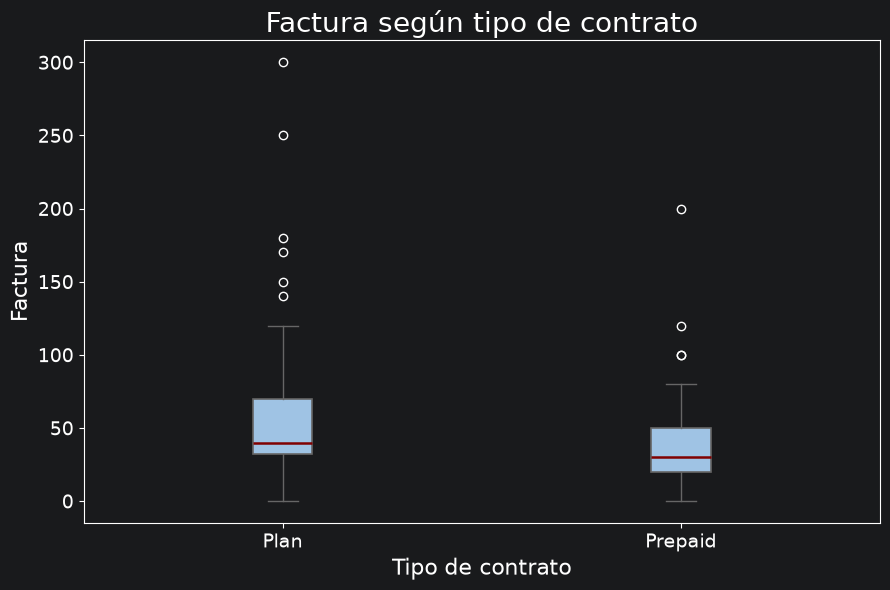

In [151]:
# Dibuja las cajas por contrato sin añadir puntos individuales.
cajas_por_plan(puntos=False)
# Cambia a puntos=True para superponer las observaciones.

**Versión simple — cajas por grupo.** pandas puede separar una variable numérica (`column`) según una categoría (`by`) en una sola llamada. Úsala como punto de partida para comparar retrasos por mes o por franjas horarias en el ejercicio.

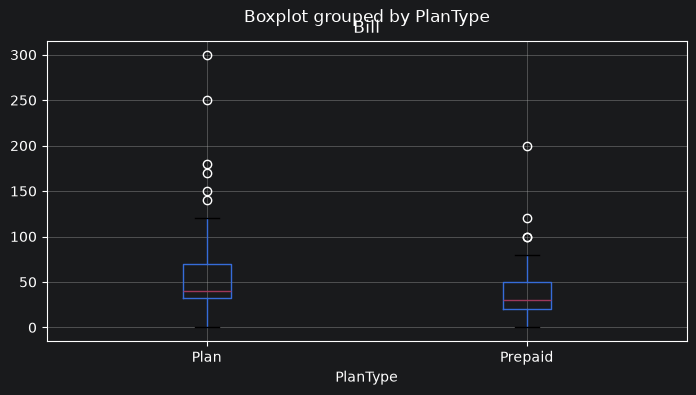

In [152]:
# Versión simple: una caja por categoría.
# Separa las facturas conocidas por tipo de contrato y dibuja sus cajas.
_ = datos.boxplot(column='Bill', by='PlanType')
# Muestra la comparación entre grupos.
plt.show()

**Microejercicio — cajas por contrato.** Dibuja en una sola línea de código cajas de `Age` separadas por `PlanType`.

In [153]:
# Pista: En la caja sencilla por contrato, cambia solo la magnitud estudiada.
# Tu línea de código:

### Ejercicio 1.6 — Comparaciones bivariantes con vuelos

Aplica las tres familias anteriores a `datos2`. **Los primeros apartados dejan espacio para tu análisis; el último incluye un ejemplo de visualización.** Antes de comparar, decide qué dos columnas intervienen y conserva solo **pares completos**; los tamaños válidos pueden diferir entre apartados.

1. Compara retraso de salida (`dep_delay`) y de llegada (`arr_delay`): correlación, dispersión y diagrama `hexbin` para localizar zonas con muchos puntos superpuestos. Los retrasos pueden ser **negativos** si un vuelo llega o sale antes de la hora prevista.
2. Estudia `arr_delay` **por mes** (`month`) mediante resúmenes y cajas. Después crea `datos2_delay` con `arr_delay > 0` y repite la comparación; recuerda que ahora describes solo vuelos que llegaron tarde.
3. Compara la hora de llegada (`arr_time`) con la **hora de salida** (`hour`) tratada como categoría. Agrupa `hour` en tramos **[0–8]**, **[9–16]** y **[17–24]** y compara otra vez.

**Cuidado con los formatos:** `arr_time` se registra como `hhmm`; una media aritmética de esos códigos **no equivale** a una hora media en minutos. Para interpretar medias o distancias temporales tendrías que convertir antes el formato y tratar adecuadamente las llegadas del día siguiente. En cambio, contar casos o comparar distribuciones por grupo no exige fingir que `hhmm` son minutos.

In [225]:
# 1.6.1a — Correlación de retrasos de salida y de llegada.
# Selecciona juntos dep_delay y arr_delay en datos2 y elimina las filas incompletas.
datos2.dropna(subset=['dep_delay' , 'arr_delay'])



,year,month,day,dep_time,dep_delay,arr_time,arr_delay,carrier,tailnum,flight,origin,dest,air_time,distance,hour,minute
0,2013,1,1,517.0,2.0,830.0,11.0,UA,N14228,1545,EWR,IAH,227.0,1400,5.0,17.0
1,2013,1,1,533.0,4.0,850.0,20.0,UA,N24211,1714,LGA,IAH,227.0,1416,5.0,33.0
2,2013,1,1,542.0,2.0,923.0,33.0,AA,N619AA,1141,JFK,MIA,160.0,1089,5.0,42.0
3,2013,1,1,544.0,-1.0,1004.0,-18.0,B6,N804JB,725,JFK,BQN,183.0,1576,5.0,44.0
4,2013,1,1,554.0,-6.0,812.0,-25.0,DL,N668DN,461,LGA,ATL,116.0,762,5.0,54.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
336765,2013,9,30,2240.0,-5.0,2334.0,-17.0,B6,N354JB,1816,JFK,SYR,41.0,209,22.0,40.0
336766,2013,9,30,2240.0,-10.0,2347.0,-20.0,B6,N281JB,2002,JFK,BUF,52.0,301,22.0,40.0
336767,2013,9,30,2241.0,-5.0,2345.0,-16.0,B6,N346JB,486,JFK,ROC,47.0,264,22.0,41.0
336768,2013,9,30,2307.0,12.0,2359.0,1.0,B6,N565JB,718,JFK,BOS,33.0,187,23.0,7.0


In [229]:
# Calcula la correlación; ¿qué indica el signo y qué significa que se acerque a 1 o a 0?
correlacion=datos2["dep_delay"].corr(datos2["arr_delay"])
print(f"Correlación: {correlacion:.4f}")


Correlación: 0.9148


#### Apartado 1b: dispersión de los retrasos

Cada punto corresponde a **un mismo vuelo**: retraso de salida en el eje horizontal y de llegada en el vertical. No basta con conocer el signo de la correlación; el gráfico permite descubrir concentraciones, dispersión y retrasos extremos que podrían influir en ella. Reutiliza los pares completos del apartado anterior.

In [155]:
# 1.6.1b — Diagrama de dispersión de los retrasos.
# Usa los mismos pares completos: salida en horizontal, llegada en vertical.
# Etiqueta los ejes y describe la dirección de la relación y la presencia de valores extremos.

#### Apartado 1c: concentración de vuelos con `hexbin`

En una dispersión, muchos vuelos pueden ocupar casi el mismo punto y quedar **ocultos**. Un mapa de hexágonos reúne observaciones cercanas; el color o la barra lateral indican cuántos vuelos caen en cada zona. Cambia la representación, **no la muestra**: usa los mismos pares completos y compara qué regiones eran difíciles de ver con puntos individuales.

In [156]:
# 1.6.1c — Hexbin: densidad de puntos.
# Reutiliza los mismos ejes y vuelos válidos, ahora mediante plt.hexbin (o ax.hexbin).
# Añade una barra de color: ¿dónde hay más vuelos superpuestos que no se distinguen en la dispersión?

#### Apartado 2: retrasos de llegada según el mes

`month` divide los vuelos en **grupos** y `arr_delay` es la magnitud que queremos comparar. Primero trabaja con **todos los vuelos con retraso conocido**: un resumen por mes indica tamaño, centro y dispersión; los diagramas de caja permiten apreciar asimetrías y valores extremos.

Después forma `datos2_delay` con `arr_delay > 0` y repite exactamente el análisis. Esta selección **cambia la población descrita**: una media de retrasos entre vuelos tardíos no es la media de retrasos de todos los vuelos. Mantén claras las etiquetas de ambos gráficos y, si comparas cajas, usa escalas interpretables.

In [157]:
# 1.6.2a — Resumen de los retrasos de llegada por mes.
# Agrupa datos2 por month y describe arr_delay: tamaño válido, media, mediana y dispersión.
# ¿Cómo afecta un arr_delay ausente al recuento y a las medidas de cada mes?

**Visualización de todos los meses.** Cada caja debe resumir `arr_delay` de un mes con datos válidos. Un retraso negativo significa llegada adelantada, no un error; conserva la misma interpretación y unidades del eje vertical al comparar los grupos.

In [158]:
# 1.6.2b — Diagramas de cajas de los retrasos por mes.
# Representa un grupo por cada month a partir de los retrasos válidos (not NAs).
# Conserva la misma escala vertical para comparar medianas, dispersión y atípicos.
# ¿Se ven valores negativos? ¿Qué indican sobre la llegada de algunos vuelos?

**Definir el subconjunto tardío.** Para repetir el análisis, conserva solo llegadas con `arr_delay > 0` y guarda el resultado aparte como `datos2_delay`. Así `datos2` continúa representando todos los vuelos para otras comparaciones. Verifica cuántas filas seleccionas antes de dibujar.

In [159]:
# 1.6.2c — Subconjunto de vuelos que llegaron con retraso.
# Crea datos2_delay a partir de datos2 usando arr_delay > 0.
# Verifica cuántos vuelos contiene y recuerda que cero y valores negativos quedan fuera.

**Repetir y contrastar.** Obtén el mismo resumen mensual y unas cajas para `datos2_delay`. Compara centro, dispersión y tamaños con los de todos los vuelos: si desaparecen valores negativos o cambian las medianas, piensa primero en el **filtro aplicado**, no en una modificación de los datos originales.

In [160]:
# 1.6.2d — Repite la comparación mensual con datos2_delay.
# Obtén el resumen por mes y dibuja otra vez las cajas, solo con vuelos que llegaron tarde.
# Compara estos resultados con los de todos los vuelos: ¿qué cambia al filtrar la muestra?

#### Apartado 3: hora de llegada según la salida

Primero trata `hour` (hora de salida) como **categoría**: agrupa vuelos con la misma hora y describe su `arr_time` conocido. Luego agrupa las horas con `pd.cut` en **[0–8]**, **[9–16]** y **[17–24]** y vuelve a comparar. Los límites deben asignar cada hora válida a **un solo tramo** y no perder la hora 0.

`arr_time` tiene formato `hhmm`: no es un número de **minutos desde medianoche**. Antes de interpretar una media o una desviación horaria conviértelo y ten presente que algunas llegadas cruzan la medianoche; las tablas de frecuencias por hora de salida sí pueden estudiarse directamente. Contrasta lo que se gana en legibilidad y lo que se pierde en detalle al reducir horas individuales a tres grupos.

In [161]:
# 1.6.3a — Hora de llegada según la hora de salida original.
# Reúne arr_time y hour con valores conocidos y agrupa por hour como categoría.
# Compara recuento y distribución de arr_time entre las horas; no confundas hhmm con minutos.
# Conserva solo vuelos con ambas horas conocidas.

**Crear tramos sin solapamientos.** Antes de comparar `arr_time` por franjas, define una columna de grupos a partir de `hour`. Comprueba con frecuencias que cada hora observada aparece exactamente una vez; un error al elegir bordes o cierre de `pd.cut` podría dejar fuera el 0 o colocar el 8 en el grupo equivocado.

In [162]:
# 1.6.3b — Tramos de hora de salida.
# Consulta pd.cut y crea en datos2 una columna para los intervalos [0–8], [9–16] y [17–24].
# Elige bordes y cierre de los intervalos para no perder la hora 0 ni duplicar fronteras.
# Comprueba con una tabla de frecuencias que cada hora válida haya quedado asignada.

**Visualizar qué cambia al agrupar horas.** Compara dos gráficos de barras apiladas: uno con **cada hora de salida** y otro con las tres franjas **[0–8]**, **[9–16]** y **[17–24]**. En cada barra, muestra qué proporción de vuelos llegó entre las **00:00 y las 11:59** y cuál entre las **12:00 y las 23:59**. Usa los mismos vuelos en ambos gráficos. ¿Qué diferencias entre horas concretas dejan de verse al agruparlas? La hora de llegada es una hora del reloj, no el tiempo que duró el vuelo.

In [163]:
# 1.6.3c — Dos gráficos de barras para comparar horas y franjas.
# Trabaja en ambos gráficos con los mismos vuelos válidos.